# Deep Armocromia — E12: Grup per Orang + Holdout Baru + Mask Biner + RGB Asli + XGBoost Stacking

Lanjutan dari E11. Alur E11 dipertahankan (face parsing → warna per region, embedding frozen, fine-tuning multi-task, ensemble, kalibrasi, prediksi selektif). Yang berubah:

| Masalah di E11 | Perubahan di E12 |
|---|---|
| Fold hanya dikelompokkan dari kemiripan embedding dengan ambang longgar | Grup = **nama orang dari nama file** (non-CelebA) ∪ near-duplicate embedding dengan ambang tetap `DUP_THR` |
| Official test sudah dipakai sejak E1 | **Holdout baru** dari train CelebA (`HOLDOUT_FRAC`), tidak ikut melatih atau memilih apa pun |
| Piksel rambut sangat gelap ikut terbuang oleh ambang "hitam" | **Mask biner** (`path_mask`) menentukan piksel yang dihitung; otomatis kembali ke ambang bila mask tidak sejajar |
| Model bisa saja menghafal bentuk siluet masking | Varian **RGB asli tanpa masking** sebagai komponen pembanding `emb_lr_orig`; `FT_INPUT` bisa diganti ke `"original"` |
| Penggabungan hanya rata-rata berbobot | **XGBoost stacking** dengan tuning acak; dipakai hanya bila lebih baik dari ensemble di OOF |
| 20% teratas tetap dilabeli "yakin" walau target akurasi tidak tercapai | Bila target tidak tercapai, **tidak ada** prediksi berlabel "yakin" |
| Sel pencatatan error (`final_metrics` tidak ada) dan menimpa `f1_score` | Diperbaiki; pencatatan hanya jalan saat `SMOKE_TEST = False` |

**Syarat Kaggle:** GPU T4, Internet ON, dataset Deep Armocromia ter-attach, Secrets `DEEP_ARMO_PASSWORD` dan `HF_TOKEN` aktif.

**Cara pakai:** jalankan dulu dengan `SMOKE_TEST = True` untuk memastikan semua sel jalan (angkanya tidak bermakna). Setelah lolos, set `SMOKE_TEST = False` lalu *Run All*.

**Aturan evaluasi:** semua keputusan (C, bobot ensemble, parameter XGBoost, temperature, ambang) diambil dari *out-of-fold* (OOF) subset CelebA. Holdout dan official test baru dipakai di bagian 9. Angka **holdout** adalah angka yang paling jujur; official test dipakai untuk membandingkan dengan E10 / FaRL.

In [1]:
# ============================================================
# 0. CONFIG
# ============================================================
EXPERIMENT_ID = "E12_GROUPED_HOLDOUT_XGBSTACK"
SEED = 42
NUM_CLASSES = 12
NUM_SEASONS = 4
SMOKE_TEST = False         # True = uji cepat alur (subset kecil, 1 epoch). Set False untuk run sebenarnya.

# --- Secrets ---
DATA_PASSWORD_SECRET_NAME = "DEEP_ARMO_PASSWORD"
HF_TOKEN_SECRET_NAME = "HF_TOKEN"

# --- Backbone (sama dengan E10/E11) ---
BACKBONE_HF_ID = "facebook/dinov3-vits16-pretrain-lvd1689m"
BACKBONE_LOCAL_DIR = None
EMB_IMG_SIZE = 224
EXTRA_MEAN_LAYERS = [4, 8]

# --- Face parsing (SegFormer CelebAMask-HQ, model publik) ---
PARSER_HF_ID = "jonathandinu/face-parsing"
PARSER_LOCAL_DIR = None
PARSE_SIZE = 512               # gambar di-letterbox ke persegi PARSE_SIZE sebelum parsing
CACHE_SIZE = 256               # gambar persegi yang disimpan di RAM untuk embedding & fine-tuning
MASK_THRESH = 8 / 255          # ambang "piksel hitam" (dipakai bila mask biner tidak tersedia / tidak sejajar)
PARSE_BATCH = 16

# --- Sumber gambar ---
USE_BINARY_MASK = True         # pakai path_mask untuk menentukan piksel valid pada statistik warna
USE_ORIGINAL_RGB = True        # tambah komponen dari RGB asli tanpa masking (emb_lr_orig) sebagai pembanding
FT_INPUT = "masked"            # "masked" (RGB-M) atau "original" (RGB asli) untuk fine-tuning

# --- Grup, holdout, cross-validation ---
N_FOLDS = 5
GROUP_COL = None               # nama kolom identitas di annotations.csv bila ada (mengalahkan aturan di bawah)
GROUP_BY_FILENAME = True       # gambar non-CelebA dikelompokkan per nama orang di nama file
DUP_THR = 0.90                 # ambang cosine near-duplicate (tetap; periksa contoh pasangan di sel 5.1)
DUP_THRESHOLDS = [0.80, 0.85, 0.90, 0.93, 0.95, 0.97]   # hanya untuk tabel pembanding
HOLDOUT_FRAC = 0.15            # porsi train (CelebA) yang disisihkan sebagai holdout baru. 0 = tanpa holdout.

# --- Komponen klasik ---
C_GRID = [3e-4, 1e-3, 3e-3, 1e-2]

# --- Fine-tuning ---
FT_IMG_SIZE = 224
FT_EPOCHS = 15
FT_BATCH = 32
FT_LR_HEAD = 1e-3
FT_LR_BACKBONE = 3e-5          # LR layer teratas backbone
FT_LLRD = 0.80                 # layer-wise LR decay (layer lebih bawah = LR lebih kecil)
FT_WD = 0.05
FT_WARMUP_EPOCHS = 1
FT_LABEL_SMOOTH = 0.1
FT_DROPOUT = 0.2
FT_AUX_W = 0.3                 # bobot tiap loss tambahan (season, undertone, karakteristik)
FT_SEEDS = [42]                # tambah seed (mis. [42, 7, 2024]) untuk ensemble lebih stabil; waktu naik linear
FT_NUM_WORKERS = 2
FT_SAVE_CKPT = True

# --- Ensemble dan XGBoost stacking ---
ENS_STEP = 0.1
USE_XGB_STACK = True
XGB_TRIALS = 20                # jumlah kombinasi parameter yang dicoba (acak)
XGB_MAX_ROUNDS = 400           # jumlah pohon maksimum; jumlah terbaik dipilih dari kurva OOF
XGB_NJOBS = 4
STACK_MIN_GAIN = 0.01          # stacking dipakai hanya bila NLL OOF lebih baik dari ensemble sebesar ini

# --- Kepercayaan dan evaluasi ---
TARGET_SELECTIVE_ACC = 0.50    # akurasi minimum yang diminta untuk prediksi berlabel "yakin"
MIN_SELECTIVE_COVERAGE = 0.05  # label "yakin" harus mencakup minimal 5% gambar
CONFORMAL_ALPHAS = [0.10, 0.20]   # 1 - alpha = cakupan himpunan kandidat (90% dan 80%)
N_BOOT = 2000
ECE_BINS = 15

RECOMPUTE = False              # True = abaikan semua cache
EXPECTED_ROWS = (4920, 4008, 912)   # total, train, test. Set None untuk melewati pengecekan.

REFERENCE = {
    "E10 (frozen DINOv3 + LR)": {"acc": 0.2939, "macro_f1": 0.2618, "top3": 0.6436, "season_acc": 0.5274, "auroc_conf": 0.6530},
    "FaRL16_E6":                {"acc": 0.3246, "macro_f1": 0.2947, "top3": 0.6579, "season_acc": 0.5263, "auroc_conf": float("nan")},
}

if SMOKE_TEST:
    FT_EPOCHS, N_FOLDS, C_GRID, N_BOOT, FT_SEEDS, XGB_TRIALS, XGB_MAX_ROUNDS = 1, 3, [1e-3], 200, [42], 2, 40
LOG_TO_REGISTRY = not SMOKE_TEST       # hasil smoke test tidak dicatat ke modellab_registry
assert FT_INPUT in ("masked", "original")

from pathlib import Path
RESULT_DIR = Path("/kaggle/working/E12" + ("_smoke" if SMOKE_TEST else ""))
RESULT_DIR.mkdir(parents=True, exist_ok=True)
print("Experiment:", EXPERIMENT_ID, "| SMOKE_TEST =", SMOKE_TEST)
print("Backbone  :", BACKBONE_LOCAL_DIR or BACKBONE_HF_ID)
print("Hasil     :", RESULT_DIR)

Experiment: E12_GROUPED_HOLDOUT_XGBSTACK | SMOKE_TEST = False
Backbone  : facebook/dinov3-vits16-pretrain-lvd1689m
Hasil     : /kaggle/working/E12


In [2]:
# ============================================================
# 1. IMPORTS
# ============================================================
import os, re, gc, json, time, math, shutil, hashlib, itertools, subprocess, warnings, random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from joblib import dump, load
from tqdm.auto import tqdm

from scipy.optimize import minimize_scalar
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, roc_auc_score
from sklearn.metrics import f1_score as sk_f1_score      # alias: nama `f1_score` dipakai sel pencatatan di akhir
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
random.seed(SEED); np.random.seed(SEED)
print("numpy", np.__version__, "| pandas", pd.__version__)
try:
    import xgboost as xgb
    print("xgboost", xgb.__version__)
except ImportError:
    xgb = None
    print("xgboost tidak terpasang -> XGBoost stacking akan dilewati.")

numpy 2.1.3 | pandas 2.3.3
xgboost 3.4.1


## 2. Dataset dan anotasi

In [3]:
# ============================================================
# 2.1 DETEKSI DATASET
# ============================================================
KAGGLE_INPUT = Path("/kaggle/input")
WORK_PREPARED_ROOT = Path("/kaggle/working/deep_armocromia_prepared")

prepared, source = [], []
for ann in KAGGLE_INPUT.rglob("annotations.csv"):
    root = ann.parent
    if (root / "RGB-M").is_dir():
        prepared.append((root, ann))
    if (root / "RGB-M.zip").is_file():
        source.append((root, ann, root / "RGB-M.zip"))

if prepared:
    MODE = "PREPARED_INPUT"
    DATA_ROOT, ANNOTATION_PATH = prepared[0]
    RGBM_ZIP = None
elif source:
    MODE = "ENCRYPTED_SOURCE"
    _, ANNOTATION_PATH, RGBM_ZIP = source[0]
    DATA_ROOT = WORK_PREPARED_ROOT
else:
    raise FileNotFoundError("annotations.csv + RGB-M/ atau RGB-M.zip tidak ditemukan di /kaggle/input.")
print("MODE:", MODE, "| ANNOTATION:", ANNOTATION_PATH)

MODE: ENCRYPTED_SOURCE | ANNOTATION: /kaggle/input/datasets/fatihitsbatulhaq/deep-armocromia/Deep Armocromia/release/annotations.csv


In [4]:
# ============================================================
# 2.2 LOAD ANNOTATIONS (+ subsample bila SMOKE_TEST)
# ============================================================
df = pd.read_csv(ANNOTATION_PATH)
print("Kolom annotations.csv:", df.columns.tolist())

SEASON_COL, SUBCLASS_COL, PARTITION_COL, MASKED_PATH_COL = "class", "sub_class", "partition", "path_rgb_masked"
missing = [c for c in [SEASON_COL, SUBCLASS_COL, PARTITION_COL, MASKED_PATH_COL, "celeba"] if c not in df.columns]
assert not missing, f"Missing columns: {missing}"

for col in [SEASON_COL, SUBCLASS_COL, PARTITION_COL]:
    df[col] = df[col].astype(str).str.strip().str.lower()
if df["celeba"].dtype != bool:
    mapped = df["celeba"].astype(str).str.strip().str.lower().map({"true": True, "1": True, "false": False, "0": False})
    assert mapped.notna().all(), "Kolom celeba punya nilai tak dikenal."
    df["celeba"] = mapped.astype(bool)
df["joint_label"] = df[SEASON_COL] + "_" + df[SUBCLASS_COL]

EXPECTED_IMAGES = len(df)          # jumlah file di RGB-M (sebelum subsample)
if EXPECTED_ROWS:
    assert len(df) == EXPECTED_ROWS[0], f"Jumlah baris {len(df)} != {EXPECTED_ROWS[0]}"
assert df[SEASON_COL].nunique() == NUM_SEASONS and df["joint_label"].nunique() == NUM_CLASSES

if SMOKE_TEST:
    tr_s = df[df[PARTITION_COL] == "train"].groupby("joint_label").sample(n=30, random_state=SEED)
    te_s = df[df[PARTITION_COL] == "test"].groupby("joint_label").sample(n=10, random_state=SEED)
    df = pd.concat([tr_s, te_s]).sort_index()
    print("SMOKE_TEST: memakai subset", len(df), "gambar.")

df = df.reset_index(drop=True)
df["row_id"] = np.arange(len(df))
display(pd.crosstab(df[PARTITION_COL], df["celeba"]))
MASK_COL = "path_mask" if "path_mask" in df.columns else None
ORIG_COL = "path_rgb_original" if "path_rgb_original" in df.columns else None

Kolom annotations.csv: ['class', 'sub_class', 'partition', 'celeba', 'path_rgb_original', 'path_rgb_masked', 'path_mask']


celeba,False,True
partition,,
test,0,912
train,1939,2069


In [5]:
# ============================================================
# 2.3 SIAPKAN FOLDER GAMBAR: RGB-M (wajib), mask biner dan RGB asli (opsional)
# ============================================================
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg"}
SRC_ROOT = ANNOTATION_PATH.parent
WORK_PREPARED_ROOT.mkdir(parents=True, exist_ok=True)
_PW = {}

def get_password():
    if "v" not in _PW:
        from kaggle_secrets import UserSecretsClient
        try:
            _PW["v"] = UserSecretsClient().get_secret(DATA_PASSWORD_SECRET_NAME)
        except Exception as e:
            raise RuntimeError(f"Secret '{DATA_PASSWORD_SECRET_NAME}' belum tersedia / belum di-enable.") from e
        assert _PW["v"]
    return _PW["v"]

def norm_rel(rel):
    return Path(str(rel).replace("\\", "/").strip().lstrip("/"))

def resolve_in(rel, top):
    p = norm_rel(rel)
    for root in (SRC_ROOT, WORK_PREPARED_ROOT):
        for c in (root / p, root / top / p):
            if c.is_file():
                return c
    return None

def resolve_column(col):
    top = norm_rel(df[col].iloc[0]).parts[0]
    return df[col].apply(lambda r: resolve_in(r, top)), top

def extract_zip(zip_path):
    pw = get_password()
    unzip_path = shutil.which("unzip")
    if unzip_path:
        r = subprocess.run([unzip_path, "-n", "-P", pw, str(zip_path), "-d", str(WORK_PREPARED_ROOT)],
                           stdout=subprocess.DEVNULL, stderr=subprocess.PIPE, text=True)
        if r.returncode not in (0, 1):
            raise RuntimeError(r.stderr[-3000:])
    else:
        import zipfile
        with zipfile.ZipFile(zip_path, "r") as z:
            z.extractall(WORK_PREPARED_ROOT, pwd=pw.encode("utf-8"))

def ensure_column(col, required):
    # Kembalikan Series path file untuk kolom `col`; ekstrak <folder>.zip bila perlu.
    paths, top = resolve_column(col)
    if not paths.notna().all():
        zips = [SRC_ROOT / f"{top}.zip"] + sorted(KAGGLE_INPUT.rglob(f"{top}.zip"))
        zips = [z for z in zips if z.is_file()]
        if zips:
            try:
                print(f"Mengekstrak {zips[0].name} ...")
                extract_zip(zips[0])
                paths, _ = resolve_column(col)
            except Exception as e:
                if required:
                    raise
                print(f"CATATAN: gagal mengekstrak {zips[0].name}: {str(e)[:300]}")
    if paths.notna().all():
        return paths
    msg = (f"Kolom '{col}': {int(paths.isna().sum())} dari {len(paths)} file tidak ditemukan "
           f"(folder '{top}' atau '{top}.zip' dicari di {SRC_ROOT}).")
    if required:
        raise FileNotFoundError(msg)
    print("CATATAN:", msg, "-> fitur ini dimatikan.")
    return None

print("Isi folder dataset:", sorted(p.name for p in SRC_ROOT.iterdir()))
df["resolved_path"] = ensure_column(MASKED_PATH_COL, required=True)

df["mask_path"], df["orig_path"] = None, None
if USE_BINARY_MASK and MASK_COL:
    _r = ensure_column(MASK_COL, required=False)
    if _r is not None:
        df["mask_path"] = _r
if (USE_ORIGINAL_RGB or FT_INPUT == "original") and ORIG_COL:
    _r = ensure_column(ORIG_COL, required=False)
    if _r is not None:
        df["orig_path"] = _r
_PW.clear()

HAS_MASK = bool(df["mask_path"].notna().all())
HAS_ORIG = bool(df["orig_path"].notna().all())
if FT_INPUT == "original" and not HAS_ORIG:
    raise FileNotFoundError("FT_INPUT='original' tetapi RGB asli tidak ditemukan. Set FT_INPUT='masked'.")
print(f"RGB-M: {len(df)} file | mask biner: {'ADA' if HAS_MASK else 'tidak dipakai'} | RGB asli: {'ADA' if HAS_ORIG else 'tidak dipakai'}")

Isi folder dataset: ['BM.zip', 'RGB-M.zip', 'RGB.zip', 'annotations.csv', 'annotations.xlsx']
Mengekstrak RGB-M.zip ...
Mengekstrak BM.zip ...
Mengekstrak RGB.zip ...
RGB-M: 4920 file | mask biner: ADA | RGB asli: ADA


In [6]:
# ============================================================
# 2.4 PATH, MD5, LABEL, SPLIT RESMI
# ============================================================
def md5_file(path, chunk=1024 * 1024):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

df["md5"] = df["resolved_path"].apply(md5_file)
assert (df.groupby("md5")[PARTITION_COL].nunique() > 1).sum() == 0, "Ada gambar identik di train dan test."
md5_all = df["md5"].to_numpy().astype(str)
N_ALL = len(df)

class_names = sorted(df["joint_label"].unique().tolist())
class2idx = {n: i for i, n in enumerate(class_names)}
idx2class = {i: n for n, i in class2idx.items()}
season_names = sorted(df[SEASON_COL].unique().tolist())
char_names = sorted(df[SUBCLASS_COL].unique().tolist())          # bright, cool, deep, light, soft, warm
season2idx = {n: i for i, n in enumerate(season_names)}
char2idx = {n: i for i, n in enumerate(char_names)}
WARM_SEASONS = {"autunno", "primavera"}                          # undertone hangat; estate & inverno = dingin

season_of = np.array([season2idx[n.split("_", 1)[0]] for n in class_names])
char_of = np.array([char2idx[n.split("_", 1)[1]] for n in class_names])
warm_of = np.array([int(n.split("_", 1)[0] in WARM_SEASONS) for n in class_names])
NUM_CHARS = len(char_names)

df["target"] = df["joint_label"].map(class2idx).astype(int)
ALL_Y = {"y12": df["target"].to_numpy(), "yS": season_of[df["target"].to_numpy()],
         "yC": char_of[df["target"].to_numpy()], "yU": warm_of[df["target"].to_numpy()]}

is_train = (df[PARTITION_COL] == "train").to_numpy()
train_rows, test_rows = np.where(is_train)[0], np.where(~is_train)[0]
if EXPECTED_ROWS and not SMOKE_TEST:
    assert len(train_rows) == EXPECTED_ROWS[1] and len(test_rows) == EXPECTED_ROWS[2]
y12 = ALL_Y["y12"][train_rows]
yte = ALL_Y["y12"][test_rows]
cel = df["celeba"].to_numpy(dtype=bool)[train_rows]

print("Kelas          :", class_names)
print("Karakteristik  :", char_names)
print("Train / test   :", len(train_rows), "/", len(test_rows), "| train CelebA:", int(cel.sum()))
print("\nContoh path (nama orang di file non-CelebA dipakai untuk pengelompokan di sel 5.2):")
for flag in (True, False):
    for p in df.loc[df["celeba"] == flag, MASKED_PATH_COL].head(4):
        print(f"  celeba={flag}: {p}")

Kelas          : ['autunno_deep', 'autunno_soft', 'autunno_warm', 'estate_cool', 'estate_light', 'estate_soft', 'inverno_bright', 'inverno_cool', 'inverno_deep', 'primavera_bright', 'primavera_light', 'primavera_warm']
Karakteristik  : ['bright', 'cool', 'deep', 'light', 'soft', 'warm']
Train / test   : 4008 / 912 | train CelebA: 2069

Contoh path (nama orang di file non-CelebA dipakai untuk pengelompokan di sel 5.2):
  celeba=True: RGB-M/train/autunno/deep/10306.png
  celeba=True: RGB-M/train/autunno/deep/10411.png
  celeba=True: RGB-M/train/autunno/deep/10552.png
  celeba=True: RGB-M/train/autunno/deep/11174.png
  celeba=False: RGB-M/train/autunno/deep/Alessandra Ambrosio 10.png
  celeba=False: RGB-M/train/autunno/deep/Alessandra Ambrosio 3.png
  celeba=False: RGB-M/train/autunno/deep/Alessandra Ambrosio 6.png
  celeba=False: RGB-M/train/autunno/deep/Alessandra Ambrosio 7.png


## 3. Face parsing dan fitur warna per region

Gambar masked masih memuat rambut, mata, bibir, dan kadang kacamata atau tangan. Model parsing memberi label per piksel, lalu statistik L\*a\*b\* dihitung **terpisah** untuk kulit, rambut, mata, bibir, dan alis. Kontras antar region (mis. kulit vs rambut) ikut dihitung karena analisis warna musiman memang bergantung pada kontras, dan selisih antar region lebih tahan terhadap perbedaan pencahayaan dibanding nilai mutlak.

Region yang tidak terdeteksi (mis. mata tertutup kacamata) diisi NaN; model gradient boosting menanganinya langsung.

Piksel yang ikut dihitung ditentukan oleh **mask biner** dataset bila tersedia dan sejajar (sel 3.2); bila tidak, oleh ambang piksel hitam seperti E11.

In [7]:
# ============================================================
# 3.1 FUNGSI WARNA (numpy murni)
# ============================================================
def rgb2lab_np(rgb):
    rgb = np.asarray(rgb, dtype=np.float64)
    lin = np.where(rgb > 0.04045, ((rgb + 0.055) / 1.055) ** 2.4, rgb / 12.92)
    M = np.array([[0.4124564, 0.3575761, 0.1804375],
                  [0.2126729, 0.7151522, 0.0721750],
                  [0.0193339, 0.1191920, 0.9503041]])
    xyz = (lin @ M.T) / np.array([0.95047, 1.0, 1.08883])
    eps, kappa = 216 / 24389, 24389 / 27
    f = np.where(xyz > eps, np.cbrt(xyz), (kappa * xyz + 16) / 116)
    return np.stack([116 * f[..., 1] - 16, 500 * (f[..., 0] - f[..., 1]), 200 * (f[..., 1] - f[..., 2])], axis=-1)

REGION_PARTS = {                       # nama label CelebAMask-HQ per region
    "skin": ["skin", "nose"],
    "hair": ["hair"],
    "eye":  ["l_eye", "r_eye"],
    "lip":  ["u_lip", "l_lip"],
    "brow": ["l_brow", "r_brow"],
}
REGION_MIN_PIX = {"skin": 400, "hair": 300, "eye": 20, "lip": 40, "brow": 30}   # pada resolusi PARSE_SIZE
BASE_STATS = ["L", "a", "b", "L_std", "chroma", "hue"]
SKIN_EXTRA = ["a_std", "b_std", "L_p10", "L_p90", "ita"]
CONTRASTS = ["dL_skin_hair", "dE_skin_hair", "dL_skin_eye", "dE_skin_eye", "dE_skin_lip", "da_lip_skin",
             "dL_skin_brow", "db_hair_skin", "L_range"]

REGION_COLS = []
for _r in REGION_PARTS:
    REGION_COLS += [f"{_r}_{s}" for s in BASE_STATS]
REGION_COLS += [f"skin_{s}" for s in SKIN_EXTRA]
REGION_COLS += [f"frac_{r}" for r in REGION_PARTS] + ["frac_glasses"]
REGION_COLS += CONTRASTS + ["all_L", "all_a", "all_b"]
COL_IX = {c: i for i, c in enumerate(REGION_COLS)}

def region_color_features(img_u8, label_map, region_ids, glasses_ids=(), valid=None):
    # img_u8: (H,W,3) uint8 ; label_map: (H,W) int ; region_ids: {region: [id label]}
    out = np.full(len(REGION_COLS), np.nan)
    if valid is None:                                   # tanpa mask biner: piksel hitam dianggap latar
        valid = img_u8.max(axis=2) > int(MASK_THRESH * 255)
    n_valid = int(valid.sum())
    if n_valid < 200:
        return out
    lab_all = rgb2lab_np(img_u8[valid].astype(np.float32) / 255.0)
    out[[COL_IX["all_L"], COL_IX["all_a"], COL_IX["all_b"]]] = np.median(lab_all, axis=0)
    lm_valid = label_map[valid]

    med = {}
    for r, ids in region_ids.items():
        m = np.isin(lm_valid, ids)
        n = int(m.sum())
        out[COL_IX[f"frac_{r}"]] = n / n_valid
        if n < REGION_MIN_PIX[r]:
            continue
        lab = lab_all[m]
        if r == "skin":                                   # buang bayangan dan highlight ekstrem
            lo, hi = np.percentile(lab[:, 0], [10, 90])
            keep = (lab[:, 0] >= lo) & (lab[:, 0] <= hi)
            if keep.sum() >= REGION_MIN_PIX[r] // 2:
                lab = lab[keep]
        md = np.median(lab, axis=0)
        med[r] = md
        out[COL_IX[f"{r}_L"]], out[COL_IX[f"{r}_a"]], out[COL_IX[f"{r}_b"]] = md
        out[COL_IX[f"{r}_L_std"]] = lab[:, 0].std()
        out[COL_IX[f"{r}_chroma"]] = np.median(np.hypot(lab[:, 1], lab[:, 2]))
        out[COL_IX[f"{r}_hue"]] = np.degrees(np.arctan2(md[2], md[1]))
        if r == "skin":
            out[COL_IX["skin_a_std"]], out[COL_IX["skin_b_std"]] = lab[:, 1].std(), lab[:, 2].std()
            out[COL_IX["skin_L_p10"]], out[COL_IX["skin_L_p90"]] = np.percentile(lab[:, 0], [10, 90])
            out[COL_IX["skin_ita"]] = np.degrees(np.arctan2(md[0] - 50.0, md[2]))
    out[COL_IX["frac_glasses"]] = float(np.isin(lm_valid, list(glasses_ids)).sum()) / n_valid if len(glasses_ids) else 0.0

    def dE(x, y):
        return float(np.linalg.norm(med[x] - med[y]))
    if "skin" in med and "hair" in med:
        out[COL_IX["dL_skin_hair"]] = med["skin"][0] - med["hair"][0]
        out[COL_IX["dE_skin_hair"]] = dE("skin", "hair")
        out[COL_IX["db_hair_skin"]] = med["hair"][2] - med["skin"][2]
    if "skin" in med and "eye" in med:
        out[COL_IX["dL_skin_eye"]] = med["skin"][0] - med["eye"][0]
        out[COL_IX["dE_skin_eye"]] = dE("skin", "eye")
    if "skin" in med and "lip" in med:
        out[COL_IX["dE_skin_lip"]] = dE("skin", "lip")
        out[COL_IX["da_lip_skin"]] = med["lip"][1] - med["skin"][1]
    if "skin" in med and "brow" in med:
        out[COL_IX["dL_skin_brow"]] = med["skin"][0] - med["brow"][0]
    Ls = [med[r][0] for r in ("skin", "hair", "eye") if r in med]
    if len(Ls) >= 2:
        out[COL_IX["L_range"]] = max(Ls) - min(Ls)
    return out

def load_squares(path, mask_path=None, orig_path=None):
    # Letterbox ke persegi (latar hitam, rasio wajah terjaga).
    # Keluaran: RGB-M (PARSE_SIZE), RGB-M (CACHE_SIZE), piksel valid (PARSE_SIZE, bool), RGB asli (CACHE_SIZE)
    with Image.open(path) as im:
        im = im.convert("RGB")
        base_size = im.size
        sq = ImageOps.pad(im, (PARSE_SIZE, PARSE_SIZE), method=Image.BILINEAR, color=(0, 0, 0))
    big = np.array(sq, dtype=np.uint8)
    small = np.array(sq.resize((CACHE_SIZE, CACHE_SIZE), Image.BILINEAR), dtype=np.uint8)
    valid = big.max(axis=2) > int(MASK_THRESH * 255)
    if mask_path is not None:
        with Image.open(mask_path) as mk:
            mk = mk.convert("L")
            if mk.size != base_size:
                mk = mk.resize(base_size, Image.NEAREST)
            arr = np.array(ImageOps.pad(mk, (PARSE_SIZE, PARSE_SIZE), method=Image.NEAREST, color=0))
        valid = arr > (arr.max() / 2.0) if arr.max() > 0 else valid
    small_o = np.zeros((1, 1, 3), dtype=np.uint8)
    if orig_path is not None:
        with Image.open(orig_path) as og:
            og = og.convert("RGB")
            if og.size != base_size:
                og = og.resize(base_size, Image.BILINEAR)
            small_o = np.array(ImageOps.pad(og, (CACHE_SIZE, CACHE_SIZE), method=Image.BILINEAR, color=(0, 0, 0)), dtype=np.uint8)
    return big, small, valid, small_o

print(len(REGION_COLS), "fitur warna per region.")

53 fitur warna per region.


In [8]:
# ============================================================
# 3.2 CEK KESEJAJARAN MASK BINER DAN RGB ASLI DENGAN RGB-M
# ============================================================
def alignment_check(n=48):
    idx = np.unique(np.linspace(0, N_ALL - 1, min(n, N_ALL)).astype(int))
    inside, filled, shift = [], [], []
    for i in idx:
        big, small, valid, small_o = load_squares(df["resolved_path"].iloc[i],
                                                  df["mask_path"].iloc[i] if HAS_MASK else None,
                                                  df["orig_path"].iloc[i] if HAS_ORIG else None)
        thr = big.max(axis=2) > int(MASK_THRESH * 255)
        both = float((thr & valid).sum())
        inside.append(both / max(float(thr.sum()), 1.0))      # piksel wajah RGB-M yang berada di dalam mask
        filled.append(both / max(float(valid.sum()), 1.0))    # piksel mask yang tidak hitam di RGB-M
        if HAS_ORIG:
            fg = small.max(axis=2) > int(MASK_THRESH * 255)
            if fg.any():
                shift.append(float(np.abs(small[fg].astype(np.float32) - small_o[fg].astype(np.float32)).mean()))
    return float(np.median(inside)), float(np.median(filled)), (float(np.median(shift)) if shift else float("nan"))

MASK_OK = False
if HAS_MASK or HAS_ORIG:
    _inside, _filled, _shift = alignment_check()
    if HAS_MASK:
        MASK_OK = (_inside >= 0.93) and (_filled >= 0.80)
        print(f"Mask biner vs RGB-M: {_inside:.1%} piksel wajah berada di dalam mask; {_filled:.1%} isi mask tidak hitam.")
        if MASK_OK:
            print("-> Mask sejajar. Statistik warna memakai mask biner (piksel rambut sangat gelap tidak lagi terbuang).")
        else:
            print("-> PERINGATAN: mask TIDAK sejajar dengan RGB-M (mungkin mask hanya wajah, atau terbalik). "
                  "Statistik warna kembali memakai ambang piksel hitam seperti E11.")
    if HAS_ORIG:
        print(f"RGB asli vs RGB-M: selisih rata-rata di area wajah = {_shift:.1f} (skala 0-255).")
        if not (_shift <= 12):
            print("-> CATATAN: RGB asli tidak sejajar piksel-per-piksel dengan RGB-M (crop/ukuran berbeda). "
                  "Tetap bisa dipakai sebagai varian gambar, tetapi periksa contoh gambarnya di sel 3.4.")
else:
    print("Mask biner dan RGB asli tidak dipakai.")

Mask biner vs RGB-M: 100.0% piksel wajah berada di dalam mask; 100.0% isi mask tidak hitam.
-> Mask sejajar. Statistik warna memakai mask biner (piksel rambut sangat gelap tidak lagi terbuang).
RGB asli vs RGB-M: selisih rata-rata di area wajah = 2.6 (skala 0-255).


In [9]:
# ============================================================
# 3.3 TORCH + MODEL PARSING
# ============================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from transformers import AutoModel, SegformerForSemanticSegmentation

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if USE_AMP else "CPU (akan sangat lambat untuk fine-tuning)")
torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True

IMNET_MEAN, IMNET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
_MEAN_T = torch.tensor(IMNET_MEAN, device=DEVICE).view(1, 3, 1, 1)
_STD_T = torch.tensor(IMNET_STD, device=DEVICE).view(1, 3, 1, 1)

def get_hf_token():
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(HF_TOKEN_SECRET_NAME)
    except Exception:
        return None

HF_TOKEN = get_hf_token() if (BACKBONE_LOCAL_DIR is None or PARSER_LOCAL_DIR is None) else None

def load_parser():
    if PARSER_LOCAL_DIR is not None:
        return SegformerForSemanticSegmentation.from_pretrained(str(PARSER_LOCAL_DIR), local_files_only=True)
    try:
        return SegformerForSemanticSegmentation.from_pretrained(PARSER_HF_ID)
    except Exception:
        return SegformerForSemanticSegmentation.from_pretrained(PARSER_HF_ID, token=HF_TOKEN)

def load_backbone():
    if BACKBONE_LOCAL_DIR is not None:
        return AutoModel.from_pretrained(str(BACKBONE_LOCAL_DIR), local_files_only=True)
    try:
        return AutoModel.from_pretrained(BACKBONE_HF_ID, token=HF_TOKEN)
    except Exception as e:
        raise RuntimeError("Gagal memuat backbone. Cek akses gated di akun HF, izin token, Internet ON, "
                           "dan transformers >= 4.57.") from e

parser = load_parser().float().to(DEVICE).eval()
for p in parser.parameters():
    p.requires_grad_(False)

LABEL_ID = {str(v): int(k) for k, v in parser.config.id2label.items()}
print("Label parser:", LABEL_ID)
REGION_IDS = {r: [LABEL_ID[n] for n in names if n in LABEL_ID] for r, names in REGION_PARTS.items()}
GLASSES_IDS = [LABEL_ID[n] for n in ["eye_g"] if n in LABEL_ID]
assert all(len(v) > 0 for v in REGION_IDS.values()), f"Nama label parser tidak cocok dengan REGION_PARTS: {REGION_IDS}"

@torch.no_grad()
def parse_u8(batch_u8):
    # batch_u8: tensor uint8 (B, S, S, 3) -> label map numpy (B, S, S)
    x = batch_u8.to(DEVICE).permute(0, 3, 1, 2).float() / 255.0
    x = (x - _MEAN_T) / _STD_T
    logits = parser(pixel_values=x).logits
    logits = F.interpolate(logits.float(), size=x.shape[-2:], mode="bilinear", align_corners=False)
    return logits.argmax(1).to(torch.uint8).cpu().numpy()

Device: cuda | Tesla T4


config.json:   0%|          | 0.00/1.69k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  339MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1172 [00:00<?, ?it/s]

Label parser: {'background': 0, 'skin': 1, 'nose': 2, 'eye_g': 3, 'l_eye': 4, 'r_eye': 5, 'l_brow': 6, 'r_brow': 7, 'l_ear': 8, 'r_ear': 9, 'mouth': 10, 'u_lip': 11, 'l_lip': 12, 'hair': 13, 'hat': 14, 'ear_r': 15, 'neck_l': 16, 'neck': 17, 'cloth': 18}


  0%|          | 0/308 [00:00<?, ?it/s]

Parsing selesai dalam 13.4 menit.


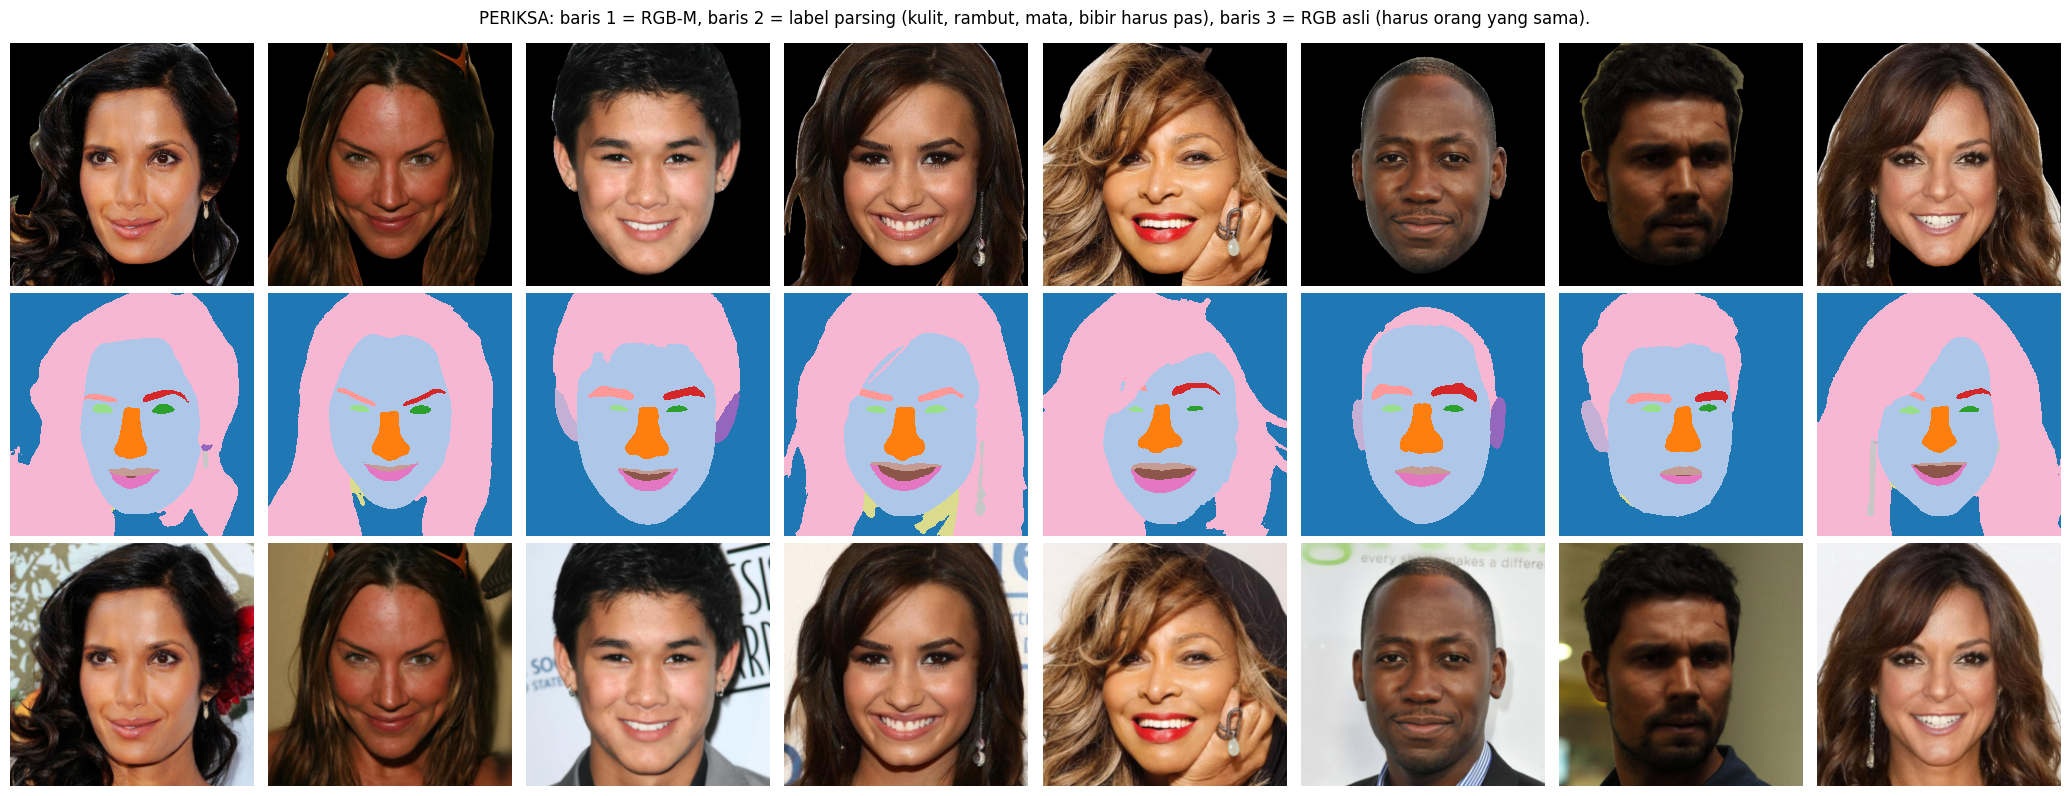

In [10]:
# ============================================================
# 3.4 PARSING SEMUA GAMBAR -> FITUR REGION + CACHE GAMBAR PERSEGI (RGB-M dan RGB asli)
# ============================================================
REG_CACHE, IMG_CACHE_PATH, ORIG_CACHE_PATH = RESULT_DIR / "region_features.npz", RESULT_DIR / "img_cache.npy", RESULT_DIR / "img_cache_orig.npy"
reg_meta = json.dumps({"parser": str(PARSER_LOCAL_DIR or PARSER_HF_ID), "parse": PARSE_SIZE, "cache": CACHE_SIZE,
                       "cols": REGION_COLS, "min": REGION_MIN_PIX, "mask": bool(MASK_OK), "orig": bool(HAS_ORIG)}, sort_keys=True)

class SquareDS(Dataset):
    def __init__(self, frame):
        self.paths = [str(p) for p in frame["resolved_path"]]
        self.masks = [str(p) for p in frame["mask_path"]] if MASK_OK else None
        self.origs = [str(p) for p in frame["orig_path"]] if HAS_ORIG else None
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        big, small, valid, small_o = load_squares(self.paths[i], self.masks[i] if self.masks else None,
                                                  self.origs[i] if self.origs else None)
        return torch.from_numpy(big), torch.from_numpy(small), torch.from_numpy(valid), torch.from_numpy(small_o)

REG = IMG_CACHE = IMG_CACHE_ORIG = None
VIS = []
if REG_CACHE.exists() and IMG_CACHE_PATH.exists() and (ORIG_CACHE_PATH.exists() or not HAS_ORIG) and not RECOMPUTE:
    z = np.load(REG_CACHE, allow_pickle=False)
    if np.array_equal(z["md5"], md5_all) and str(z["meta"]) == reg_meta:
        REG, IMG_CACHE = z["reg"], np.load(IMG_CACHE_PATH)
        IMG_CACHE_ORIG = np.load(ORIG_CACHE_PATH) if HAS_ORIG else None
        print("Cache parsing dipakai.")

if REG is None:
    loader = DataLoader(SquareDS(df), batch_size=PARSE_BATCH, shuffle=False, num_workers=FT_NUM_WORKERS)
    reg_list, img_list, orig_list, t0 = [], [], [], time.time()
    for big, small, valid, small_o in tqdm(loader):
        maps = parse_u8(big)
        big_np, valid_np = big.numpy(), valid.numpy()
        for j in range(len(big_np)):
            reg_list.append(region_color_features(big_np[j], maps[j], REGION_IDS, GLASSES_IDS, valid_np[j]))
            if len(VIS) < 8:
                VIS.append((big_np[j].copy(), maps[j].copy(), small_o[j].numpy().copy()))
        img_list.append(small.numpy())
        if HAS_ORIG:
            orig_list.append(small_o.numpy())
    REG, IMG_CACHE = np.stack(reg_list), np.concatenate(img_list)
    IMG_CACHE_ORIG = np.concatenate(orig_list) if HAS_ORIG else None
    np.savez_compressed(REG_CACHE, reg=REG, md5=md5_all, meta=reg_meta)
    np.save(IMG_CACHE_PATH, IMG_CACHE)
    if HAS_ORIG:
        np.save(ORIG_CACHE_PATH, IMG_CACHE_ORIG)
    print(f"Parsing selesai dalam {(time.time() - t0) / 60:.1f} menit.")
assert REG.shape == (N_ALL, len(REGION_COLS)) and IMG_CACHE.shape == (N_ALL, CACHE_SIZE, CACHE_SIZE, 3)
assert IMG_CACHE_ORIG is None or IMG_CACHE_ORIG.shape == IMG_CACHE.shape

if VIS:
    n_row = 3 if HAS_ORIG else 2
    fig, axes = plt.subplots(n_row, len(VIS), figsize=(2.6 * len(VIS), 2.7 * n_row))
    for j, (im, mp, og) in enumerate(VIS):
        axes[0, j].imshow(im); axes[0, j].axis("off")
        axes[1, j].imshow(mp, cmap="tab20", vmin=0, vmax=19, interpolation="nearest"); axes[1, j].axis("off")
        if HAS_ORIG:
            axes[2, j].imshow(og); axes[2, j].axis("off")
    plt.suptitle("PERIKSA: baris 1 = RGB-M, baris 2 = label parsing (kulit, rambut, mata, bibir harus pas)"
                 + (", baris 3 = RGB asli (harus orang yang sama)." if HAS_ORIG else "."))
    plt.tight_layout(); plt.show()

Proporsi gambar dengan region terdeteksi: {'skin': 1.0, 'hair': 0.978, 'eye': 0.986, 'lip': 0.998, 'brow': 0.982}


,mean,std,min,max
skin_L,64.50,11.17,8.45,96.23
skin_a,15.97,5.35,-6.24,52.08
skin_b,20.55,7.48,-30.66,62.69
skin_ita,33.09,26.64,-171.48,162.58
hair_L,26.91,19.24,0.00,92.89
eye_L,31.26,13.38,0.38,85.32
lip_a,30.28,9.22,-19.40,70.31
dL_skin_hair,38.04,19.20,-27.33,84.62


,feature,n,auc_warm_vs_cool,auc_light_vs_deep,sep_undertone
7,hair_a,3929,0.687,0.730,0.187
10,hair_chroma,3929,0.665,0.900,0.165
8,hair_b,3929,0.659,0.913,0.159
52,all_b,4008,0.656,0.702,0.156
51,all_a,4008,0.650,0.532,0.150
4,skin_chroma,4006,0.624,0.356,0.124
2,skin_b,4006,0.619,0.360,0.119
28,brow_chroma,3949,0.614,0.692,0.114
26,brow_b,3949,0.610,0.673,0.110
25,brow_a,3949,0.602,0.683,0.102


AUROC 0,5 = tidak memisahkan. Jika fitur teratas untuk undertone hanya ~0,55-0,60, sinyal warna untuk undertone memang lemah di dataset ini.


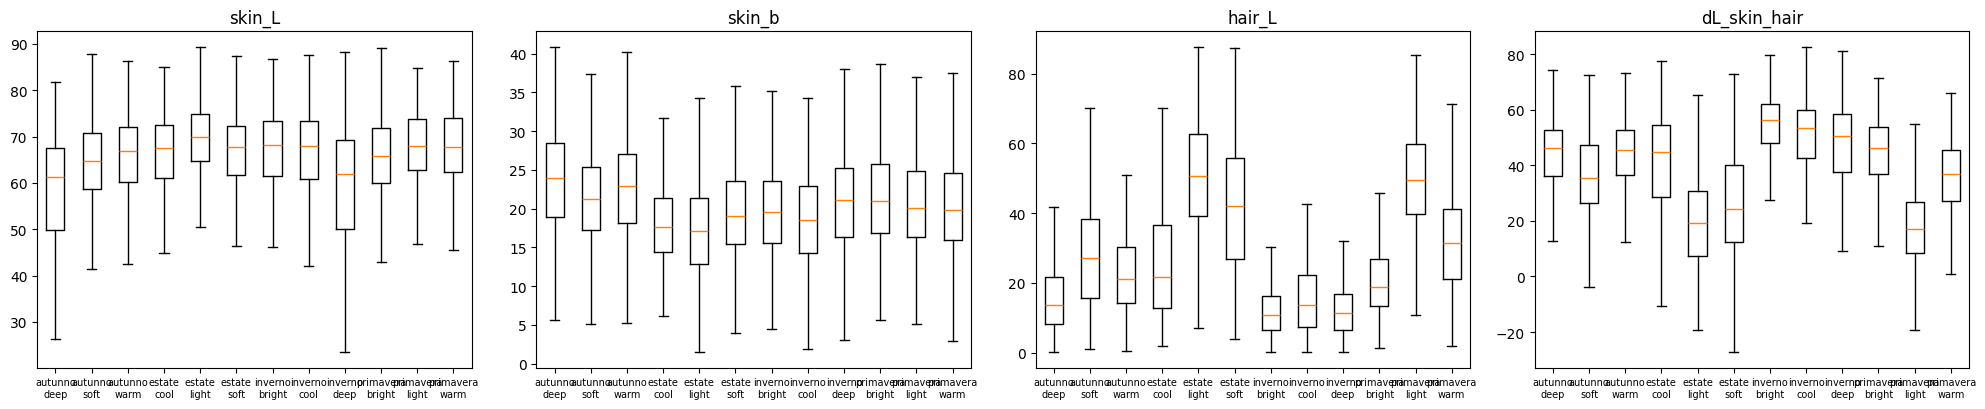

In [11]:
# ============================================================
# 3.5 DIAGNOSTIK FITUR REGION
# ============================================================
reg_df = pd.DataFrame(REG, columns=REGION_COLS)
found = {r: float(reg_df[f"{r}_L"].notna().mean()) for r in REGION_PARTS}
print("Proporsi gambar dengan region terdeteksi:", {k: round(v, 3) for k, v in found.items()})
if found["skin"] < 0.9:
    print("PERINGATAN: kulit terdeteksi di <90% gambar. Periksa visual parsing di atas sebelum mempercayai fitur ini.")
display(reg_df[["skin_L", "skin_a", "skin_b", "skin_ita", "hair_L", "eye_L", "lip_a", "dL_skin_hair"]].describe().T[["mean", "std", "min", "max"]].round(2))

# Seberapa kuat tiap fitur memisahkan undertone (hangat vs dingin) dan kedalaman? AUROC univariat, train saja.
tr_reg = reg_df.iloc[train_rows]
yU_tr, yC_tr = ALL_Y["yU"][train_rows], ALL_Y["yC"][train_rows]
rows = []
for c in REGION_COLS:
    v = tr_reg[c].to_numpy()
    ok = np.isfinite(v)
    if ok.sum() < 50 or len(np.unique(yU_tr[ok])) < 2:
        continue
    row = {"feature": c, "n": int(ok.sum()), "auc_warm_vs_cool": roc_auc_score(yU_tr[ok], v[ok])}
    if "deep" in char2idx and "light" in char2idx:
        dl = ok & np.isin(yC_tr, [char2idx["deep"], char2idx["light"]])
        if dl.sum() >= 50 and len(np.unique(yC_tr[dl])) == 2:
            row["auc_light_vs_deep"] = roc_auc_score((yC_tr[dl] == char2idx["light"]).astype(int), v[dl])
    rows.append(row)
auc_df = pd.DataFrame(rows)
auc_df["sep_undertone"] = (auc_df["auc_warm_vs_cool"] - 0.5).abs()
display(auc_df.sort_values("sep_undertone", ascending=False).head(12).round(3))
print("AUROC 0,5 = tidak memisahkan. Jika fitur teratas untuk undertone hanya ~0,55-0,60, sinyal warna untuk undertone memang lemah di dataset ini.")
auc_df.to_csv(RESULT_DIR / "E12_region_feature_auc.csv", index=False)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
tmp = tr_reg.copy(); tmp["joint_label"] = df["joint_label"].to_numpy()[train_rows]
for ax, col in zip(axes, ["skin_L", "skin_b", "hair_L", "dL_skin_hair"]):
    data = [tmp.loc[(tmp["joint_label"] == n) & tmp[col].notna(), col].values for n in class_names]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks(range(1, NUM_CLASSES + 1)); ax.set_xticklabels([n.replace("_", "\n") for n in class_names], fontsize=7)
    ax.set_title(col)
plt.tight_layout(); plt.show()

## 4. Embedding frozen (komponen klasik + deteksi near-duplicate)

In [12]:
# ============================================================
# 4.1 EMBEDDING FROZEN DARI CACHE GAMBAR PERSEGI (RGB-M, dan RGB asli bila ada)
# ============================================================
emb_meta = json.dumps({"model": str(BACKBONE_LOCAL_DIR or BACKBONE_HF_ID), "img": EMB_IMG_SIZE, "cache": CACHE_SIZE,
                       "layers": EXTRA_MEAN_LAYERS}, sort_keys=True)

frozen = load_backbone().float().to(DEVICE).eval()
for p in frozen.parameters():
    p.requires_grad_(False)
HIDDEN = int(frozen.config.hidden_size)
N_LAYERS = int(frozen.config.num_hidden_layers)
N_PREFIX = 1 + int(getattr(frozen.config, "num_register_tokens", 0))
assert all(0 < l < N_LAYERS for l in EXTRA_MEAN_LAYERS)

def u8_to_input(batch_u8_np, size):
    x = torch.from_numpy(batch_u8_np).to(DEVICE).permute(0, 3, 1, 2).float() / 255.0
    if x.shape[-1] != size:
        x = F.interpolate(x, size=(size, size), mode="bilinear", antialias=True, align_corners=False)
    return (x - _MEAN_T) / _STD_T

@torch.no_grad()
def embed_u8(batch_u8_np):
    x = u8_to_input(batch_u8_np, EMB_IMG_SIZE)
    acc = None
    for xx in (x, torch.flip(x, dims=[3])):
        out = frozen(pixel_values=xx, output_hidden_states=True)
        last, hs = out.last_hidden_state, out.hidden_states
        f = {"cls_last": last[:, 0], "mean_last": last[:, N_PREFIX:].mean(1)}
        for li in EXTRA_MEAN_LAYERS:
            f[f"mean_L{li}"] = hs[li][:, N_PREFIX:].mean(1)
        acc = f if acc is None else {k: acc[k] + f[k] for k in f}
    return {k: (v / 2).float().cpu().numpy() for k, v in acc.items()}

def compute_embeddings(img_cache, cache_path, tag):
    if cache_path.exists() and not RECOMPUTE:
        z = np.load(cache_path, allow_pickle=False)
        if np.array_equal(z["md5"], md5_all) and str(z["meta"]) == emb_meta:
            print(f"Cache embedding ({tag}) dipakai.")
            return {k: z[k] for k in z.files if k not in ("md5", "meta")}
    chunks = {}
    for s in tqdm(range(0, N_ALL, 64), desc=f"embedding {tag}"):
        for k, v in embed_u8(img_cache[s:s + 64]).items():
            chunks.setdefault(k, []).append(v)
    emb = {k: np.concatenate(v) for k, v in chunks.items()}
    np.savez_compressed(cache_path, md5=md5_all, meta=emb_meta, **emb)
    return emb

EMB = compute_embeddings(IMG_CACHE, RESULT_DIR / "frozen_embeddings.npz", "RGB-M")
EMB_ORIG = compute_embeddings(IMG_CACHE_ORIG, RESULT_DIR / "frozen_embeddings_orig.npz", "RGB asli") if (USE_ORIGINAL_RGB and HAS_ORIG) else None
for _e in (EMB, EMB_ORIG):
    assert _e is None or all(v.shape == (N_ALL, HIDDEN) and np.isfinite(v).all() for v in _e.values())
print({k: v.shape for k, v in EMB.items()}, "| RGB asli:", "ADA" if EMB_ORIG is not None else "tidak dipakai")

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

embedding RGB-M:   0%|          | 0/77 [00:00<?, ?it/s]

embedding RGB asli:   0%|          | 0/77 [00:00<?, ?it/s]

{'cls_last': (4920, 384), 'mean_last': (4920, 384), 'mean_L4': (4920, 384), 'mean_L8': (4920, 384)} | RGB asli: ADA


## 5. Grup per orang, holdout baru, dan fold CV

Label sub-season melekat pada **orang**, bukan pada foto. Bila foto orang yang sama ada di data latih dan data validasi, model bisa menebak benar hanya dengan mengenali wajahnya. Karena itu semua foto satu orang harus berada di sisi yang sama.

`annotations.csv` tidak punya kolom identitas, jadi grup dibentuk dari dua sumber:

1. **Nama file** untuk gambar non-CelebA (mis. `jessica alba 9.png` → `jessica alba`).
2. **Near-duplicate embedding** untuk semua gambar, dengan ambang tetap `DUP_THR`. Ini hanya menangkap foto yang hampir sama; dua foto berbeda dari orang CelebA yang sama **belum tentu** tertangkap. Keterbatasan ini perlu disebut saat melaporkan hasil.

Setelah grup terbentuk, sebagian train CelebA disisihkan sebagai **holdout baru**. Holdout tidak dipakai melatih, memilih parameter, atau mengkalibrasi; ia hanya dibuka di bagian 9.

,thr,pairs,grouped_frac,largest_group,pairs_train_x_test,dipakai
0,0.80,2586,0.1539,494,901,
1,0.85,642,0.0630,93,235,
2,0.90,109,0.0215,32,43,<--
3,0.93,23,0.0081,5,6,
4,0.95,7,0.0026,3,1,
5,0.97,4,0.0016,2,1,


Ambang near-duplicate dipakai: 0.9 -> 109 pasangan, 43 di antaranya menyeberang train/test resmi.
CATATAN: pasangan yang menyeberang train/test membuat angka official test sedikit optimistis; holdout tidak terkena.


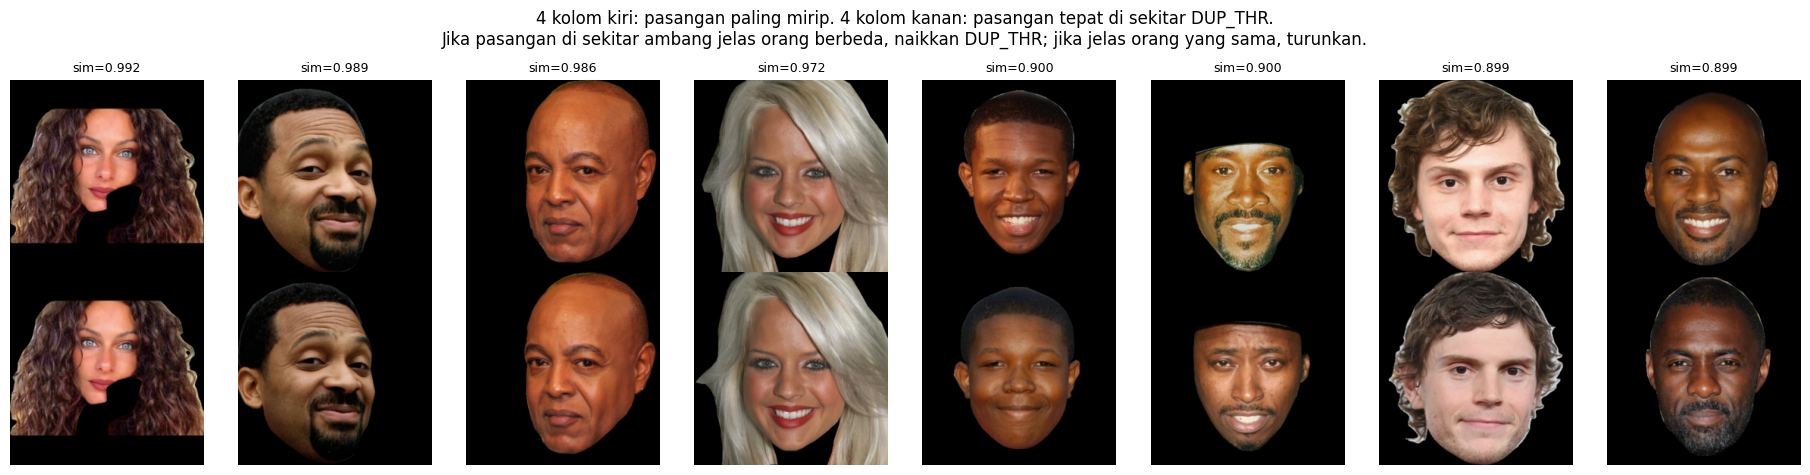

34203

In [13]:
# ============================================================
# 5.1 DETEKSI NEAR-DUPLICATE (ambang tetap DUP_THR)
# ============================================================
E = EMB["cls_last"].astype(np.float32)
E = E - E[train_rows].mean(0, keepdims=True)                    # buang komponen umum "wajah di latar hitam"
E /= np.clip(np.linalg.norm(E, axis=1, keepdims=True), 1e-8, None)
SIM = E @ E.T
np.fill_diagonal(SIM, -1.0)
iu, ju = np.triu_indices(N_ALL, k=1)
sim_u = SIM[iu, ju]

def components_at(thr):
    m = sim_u >= thr
    g = coo_matrix((np.ones(int(m.sum())), (iu[m], ju[m])), shape=(N_ALL, N_ALL))
    _, lab = connected_components(g, directed=False)
    return lab, int(m.sum()), m

rows = []
for thr in sorted(set(DUP_THRESHOLDS + [DUP_THR])):
    lab, n_pairs, m = components_at(thr)
    sizes = np.bincount(lab)
    rows.append({"thr": thr, "pairs": n_pairs, "grouped_frac": float((sizes[lab] > 1).mean()),
                 "largest_group": int(sizes.max()), "pairs_train_x_test": int((is_train[iu[m]] != is_train[ju[m]]).sum()),
                 "dipakai": "<--" if thr == DUP_THR else ""})
dup_df = pd.DataFrame(rows)
display(dup_df.round(4))

_, _, m_sel = components_at(DUP_THR)
dup_pairs = np.stack([iu[m_sel], ju[m_sel]], axis=1)
n_cross = int((is_train[dup_pairs[:, 0]] != is_train[dup_pairs[:, 1]]).sum())
print(f"Ambang near-duplicate dipakai: {DUP_THR} -> {len(dup_pairs)} pasangan, {n_cross} di antaranya menyeberang train/test resmi.")
if n_cross:
    print("CATATAN: pasangan yang menyeberang train/test membuat angka official test sedikit optimistis; holdout tidak terkena.")

# Contoh pasangan untuk diperiksa mata: paling mirip, dan tepat di sekitar ambang
order = np.argsort(-sim_u)
show = list(order[:4]) + list(np.argsort(np.abs(sim_u - DUP_THR))[:4])
fig, axes = plt.subplots(2, len(show), figsize=(2.3 * len(show), 4.8))
for c, k in enumerate(show):
    for r, idx in enumerate((iu[k], ju[k])):
        axes[r, c].imshow(IMG_CACHE[idx]); axes[r, c].axis("off")
    axes[0, c].set_title(f"sim={sim_u[k]:.3f}", fontsize=9)
plt.suptitle("4 kolom kiri: pasangan paling mirip. 4 kolom kanan: pasangan tepat di sekitar DUP_THR.\n"
             "Jika pasangan di sekitar ambang jelas orang berbeda, naikkan DUP_THR; jika jelas orang yang sama, turunkan.")
plt.tight_layout(); plt.show()
del SIM, sim_u, iu, ju, E; gc.collect()

In [14]:
# ============================================================
# 5.2 GRUP PER ORANG -> HOLDOUT BARU -> FOLD CV
# ============================================================
def name_key(rel):
    # "RGB-M/train/autunno/deep/Elisabetta-Canalis 9.png" -> "elisabetta canalis"
    s = Path(str(rel).replace("\\", "/")).stem.lower()
    s = re.sub(r"[_\-.]+", " ", s)
    prev = None
    while prev != s:
        prev = s
        s = re.sub(r"\s*\(?\d+\)?\s*$", "", s).strip()
    return re.sub(r"\s+", " ", s)

is_cel_all = df["celeba"].to_numpy(dtype=bool)
edges, name_groups = ([dup_pairs] if len(dup_pairs) else []), {}
if GROUP_BY_FILENAME:
    keys = df[MASKED_PATH_COL].map(name_key).to_numpy()
    for i in np.where(~is_cel_all)[0]:
        if len(keys[i]) >= 3:
            name_groups.setdefault(keys[i], []).append(int(i))
    for members in name_groups.values():
        if len(members) > 1:
            edges.append(np.array([[members[0], j] for j in members[1:]]))

if GROUP_COL:
    groups_all = df[GROUP_COL].astype(str).to_numpy(); group_src = f"kolom '{GROUP_COL}'"
else:
    if edges:
        e = np.concatenate(edges)
        _, lab = connected_components(coo_matrix((np.ones(len(e)), (e[:, 0], e[:, 1])), shape=(N_ALL, N_ALL)), directed=False)
    else:
        lab = np.arange(N_ALL)
    groups_all = lab.astype(str); group_src = "nama file + near-duplicate"

if name_groups:
    ng = pd.Series({k: len(v) for k, v in name_groups.items()}).sort_values(ascending=False)
    print(f"Nama orang unik (non-CelebA): {len(ng)} | punya lebih dari 1 foto: {int((ng > 1).sum())} | "
          f"foto non-CelebA: {int((~is_cel_all).sum())}")
    print("Nama dengan foto terbanyak (periksa: apakah pemotongan nama sudah benar?):", {k: int(v) for k, v in ng.head(8).items()})
    multi_label = {k: sorted(df["joint_label"].iloc[v].unique()) for k, v in name_groups.items() if df["joint_label"].iloc[v].nunique() > 1}
    print(f"Orang dengan lebih dari 1 label sub-season: {len(multi_label)} dari {len(ng)}"
          + (f" | contoh: {dict(list(multi_label.items())[:5])}" if multi_label else ""))
    if multi_label:
        print("  -> label tidak konsisten untuk orang yang sama = noise label; ini membatasi akurasi maksimum yang bisa dicapai.")
    cross_names = [k for k, v in name_groups.items() if len(set(is_train[v])) > 1]
    print(f"Orang (dari nama file) yang muncul di train DAN test resmi: {len(cross_names)}")

# --- Holdout baru: satu lipatan StratifiedGroupKFold, hanya baris CelebA yang disisihkan ---
official_train_rows = train_rows.copy()
g_off = groups_all[official_train_rows]
strata_all = (df["joint_label"] + "|" + df["celeba"].astype(int).astype(str)).to_numpy()
if HOLDOUT_FRAC and HOLDOUT_FRAC > 0:
    n_sp = max(2, int(round(1.0 / HOLDOUT_FRAC)))
    sp = StratifiedGroupKFold(n_splits=n_sp, shuffle=True, random_state=SEED + 1)
    _, cand = next(iter(sp.split(np.zeros(len(g_off)), strata_all[official_train_rows], groups=g_off)))
    ho_local = cand[is_cel_all[official_train_rows][cand]]
    hold_groups = set(g_off[ho_local])
    keep_local = np.array([i for i in range(len(g_off)) if g_off[i] not in hold_groups])
    hold_rows, train_rows = official_train_rows[ho_local], official_train_rows[keep_local]
    n_dropped = len(official_train_rows) - len(hold_rows) - len(train_rows)
else:
    hold_rows, n_dropped = np.array([], dtype=int), 0
assert len(set(groups_all[hold_rows]) & set(groups_all[train_rows])) == 0, "Grup bocor antara holdout dan train."

# Mulai dari sini `train_rows` = data pengembangan (official train dikurangi holdout).
y12 = ALL_Y["y12"][train_rows]
yho = ALL_Y["y12"][hold_rows]
cel = is_cel_all[train_rows]
groups_tr = groups_all[train_rows]
strata = strata_all[train_rows]
print(f"\nOfficial train {len(official_train_rows)} -> pengembangan {len(train_rows)} (CelebA {int(cel.sum())}) + holdout {len(hold_rows)}"
      + (f" (+{n_dropped} gambar non-CelebA dibuang karena segrup dengan holdout)" if n_dropped else ""))

splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(splitter.split(np.zeros(len(strata)), strata, groups=groups_tr))
fold_id = np.zeros(len(strata), dtype=int)
for k, (_, va) in enumerate(folds):
    fold_id[va] = k
assert all(len(set(groups_tr[tr]) & set(groups_tr[va])) == 0 for tr, va in folds), "Grup bocor antar fold."
FOLD_HASH = hashlib.md5(fold_id.tobytes() + train_rows.astype(np.int64).tobytes()).hexdigest()[:10]
print(f"CV: StratifiedGroupKFold ({group_src}) | grup unik: {len(set(groups_tr))} dari {len(groups_tr)} gambar")
display(pd.DataFrame({"n": np.bincount(fold_id), "n_celeba": np.bincount(fold_id, weights=cel).astype(int)}).T)

Nama orang unik (non-CelebA): 350 | punya lebih dari 1 foto: 176 | foto non-CelebA: 1939
Nama dengan foto terbanyak (periksa: apakah pemotongan nama sudah benar?): {'images': 396, 'paola turani': 59, 'gillian anderson': 48, 'jessica chastain': 35, 'cristiana capotondi': 34, 'angelina jolie': 33, 'alexa chung': 31, 'lily collins': 27}
Orang dengan lebih dari 1 label sub-season: 4 dari 350 | contoh: {'david beckham': ['autunno_soft', 'autunno_warm'], 'evan peters': ['autunno_soft', 'autunno_warm'], 'debra messing': ['autunno_warm', 'primavera_bright'], 'images': ['estate_cool', 'estate_light', 'estate_soft']}
  -> label tidak konsisten untuk orang yang sama = noise label; ini membatasi akurasi maksimum yang bisa dicapai.
Orang (dari nama file) yang muncul di train DAN test resmi: 0

Official train 4008 -> pengembangan 3718 (CelebA 1779) + holdout 290
CV: StratifiedGroupKFold (nama file + near-duplicate) | grup unik: 2092 dari 3718 gambar


,0,1,2,3,4
n,654,696,682,1098,588
n_celeba,346,349,347,344,393


## 6. Metrik dan komponen klasik

- `emb_lr`: logistic regression di atas embedding frozen multi-layer (pemenang E10, grid C diperluas ke bawah).
- `color_hgb`: gradient boosting di atas fitur warna per region.
- `emb_lr_orig`: sama dengan `emb_lr` tetapi dari **RGB asli tanpa masking** (hanya bila tersedia). Pembanding untuk menjawab apakah masking membantu.

In [15]:
# ============================================================
# 6.1 METRIK, KALIBRASI, POOLING
# ============================================================
def ece_score(correct, conf, n_bins=ECE_BINS):
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        m = (conf >= edges[i]) & ((conf < edges[i + 1]) if i < n_bins - 1 else (conf <= edges[i + 1]))
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)

def risk_coverage(correct, conf):
    order = np.argsort(-conf, kind="stable")
    c = correct[order].astype(float)
    k = np.arange(1, len(c) + 1)
    return k / len(c), np.cumsum(c) / k, conf[order]

def topk_hit(y, probs, k):
    idx = np.argsort(-probs, axis=1)[:, :k]
    return float((idx == y[:, None]).any(1).mean())

def group_probs(probs, mapping, n):
    return np.stack([probs[:, mapping == g].sum(1) for g in range(n)], axis=1)

def full_metrics(y, probs):
    pred, conf = probs.argmax(1), probs.max(1)
    correct = pred == y
    _, rec, f1c, _ = precision_recall_fscore_support(y, pred, labels=list(range(NUM_CLASSES)), zero_division=0)
    tp = np.clip(probs[np.arange(len(y)), y], 1e-12, 1.0)
    cov, cacc, _ = risk_coverage(correct, conf)
    pU = group_probs(probs, warm_of, 2)
    return {
        "acc": float(correct.mean()),
        "macro_f1": float(f1c.mean()),
        "top2": topk_hit(y, probs, 2),
        "top3": topk_hit(y, probs, 3),
        "season_acc": float((group_probs(probs, season_of, NUM_SEASONS).argmax(1) == season_of[y]).mean()),
        "undertone_acc": float((pU.argmax(1) == warm_of[y]).mean()),
        "char_acc": float((group_probs(probs, char_of, NUM_CHARS).argmax(1) == char_of[y]).mean()),
        "worst3_recall": float(np.sort(rec)[:3].mean()),
        "nll": float(-np.log(tp).mean()),
        "ece": ece_score(correct, conf),
        "auroc_conf": float(roc_auc_score(correct, conf)) if 0 < correct.sum() < len(correct) else float("nan"),
        "mean_conf": float(conf.mean()),
        "acc_at_20cov": float(cacc[max(int(0.2 * len(cacc)) - 1, 0)]),
        "acc_at_50cov": float(cacc[max(int(0.5 * len(cacc)) - 1, 0)]),
    }

def apply_temperature(p, T):
    z = np.log(np.clip(p, 1e-12, 1.0)) / float(T)
    z -= z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def fit_temperature(y, p, lo=0.3, hi=5.0):
    def nll(T):
        q = apply_temperature(p, T)
        return float(-np.log(np.clip(q[np.arange(len(y)), y], 1e-12, 1)).mean())
    return float(minimize_scalar(nll, bounds=(lo, hi), method="bounded").x)

def pool(prob_list, weights):
    # log-linear pooling (rata-rata geometrik berbobot), dinormalisasi ulang
    z = sum(w * np.log(np.clip(p, 1e-12, 1.0)) for p, w in zip(prob_list, weights))
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def proba_full(model, X, n_classes=NUM_CLASSES):
    p = model.predict_proba(X)
    out = np.zeros((len(X), n_classes))
    out[:, model.classes_] = p
    return out

def cv_oof(X, y, make_fn):
    oof = np.zeros((len(y), NUM_CLASSES))
    for tr, va in folds:
        oof[va] = proba_full(make_fn().fit(X[tr], y[tr]), X[va])
    return oof

SHOW = ["acc", "macro_f1", "top3", "season_acc", "undertone_acc", "char_acc", "nll", "ece", "auroc_conf", "acc_at_20cov"]
COMP_OOF, COMP_TEST, COMP_MODEL = {}, {}, {}
print("Helper siap.")

Helper siap.


In [16]:
# ============================================================
# 6.2 KOMPONEN emb_lr, emb_lr_orig, color_hgb (OOF + prediksi holdout & test)
# ============================================================
COMP_OOF, COMP_TEST, COMP_HOLD, COMP_MODEL, BEST_C = {}, {}, {}, {}, {}
EMB_KEYS = ["cls_last", "mean_last"] + [f"mean_L{l}" for l in EXTRA_MEAN_LAYERS]

def make_lr(C):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000))

def hold_proba(model, X):
    return proba_full(model, X[hold_rows]) if len(hold_rows) else np.zeros((0, NUM_CLASSES))

def add_component(name, X, make_fn, oof=None):
    COMP_OOF[name] = cv_oof(X[train_rows], y12, make_fn) if oof is None else oof
    COMP_MODEL[name] = make_fn().fit(X[train_rows], y12)
    COMP_TEST[name] = proba_full(COMP_MODEL[name], X[test_rows])
    COMP_HOLD[name] = hold_proba(COMP_MODEL[name], X)

X_EMB = {"emb_lr": np.hstack([EMB[k] for k in EMB_KEYS]).astype(np.float64)}
if EMB_ORIG is not None:
    X_EMB["emb_lr_orig"] = np.hstack([EMB_ORIG[k] for k in EMB_KEYS]).astype(np.float64)

for name, X in X_EMB.items():
    rows, lr_oofs = [], {}
    for C in C_GRID:
        t0 = time.time()
        lr_oofs[C] = cv_oof(X[train_rows], y12, lambda: make_lr(C))
        m = full_metrics(y12[cel], lr_oofs[C][cel])
        rows.append({"komponen": name, "C": C, **{k: m[k] for k in ["acc", "macro_f1", "nll", "auroc_conf"]}, "sec": round(time.time() - t0, 1)})
    lr_df = pd.DataFrame(rows)
    display(lr_df.round(4))
    BEST_C[name] = float(lr_df.sort_values("nll").iloc[0]["C"])
    if len(C_GRID) > 1 and BEST_C[name] in (min(C_GRID), max(C_GRID)):
        print(f"CATATAN: C terbaik {name} ({BEST_C[name]}) di tepi grid {C_GRID}. Perluas grid ke arah itu bila ingin menyetel lebih jauh.")
    add_component(name, X, lambda: make_lr(BEST_C[name]), oof=lr_oofs[BEST_C[name]])

def make_hgb():
    return HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, max_depth=4, l2_regularization=1.0,
                                          early_stopping=True, validation_fraction=0.15, n_iter_no_change=25,
                                          random_state=SEED)
REG_KEEP = np.where(np.isfinite(REG[train_rows]).mean(0) >= 0.02)[0]      # buang kolom yang hampir selalu kosong
dropped = [REGION_COLS[i] for i in range(len(REGION_COLS)) if i not in set(REG_KEEP)]
if dropped:
    print("Kolom region dibuang (region hampir tidak pernah terdeteksi):", dropped)
X_reg = REG[:, REG_KEEP].astype(np.float64)
add_component("color_hgb", X_reg, make_hgb)

display(pd.DataFrame({k: {s: full_metrics(y12[cel], v[cel])[s] for s in SHOW} for k, v in COMP_OOF.items()}).T.round(4))
print("Baris di atas = OOF subset CelebA.")
if "emb_lr_orig" in COMP_OOF:
    print("Bandingkan emb_lr (RGB-M) dengan emb_lr_orig (RGB asli): bila emb_lr_orig setara atau lebih baik, "
          "masking tidak membantu dan fine-tuning layak dicoba dengan FT_INPUT='original'.")

,komponen,C,acc,macro_f1,nll,auroc_conf,sec
0,emb_lr,0.0003,0.2693,0.2352,1.9964,0.6220,44.7
1,emb_lr,0.0010,0.2788,0.2521,1.9582,0.6266,56.7
2,emb_lr,0.0030,0.2923,0.2680,1.9954,0.6100,69.4
3,emb_lr,0.0100,0.2754,0.2517,2.1448,0.6364,102.4


,komponen,C,acc,macro_f1,nll,auroc_conf,sec
0,emb_lr_orig,0.0003,0.2456,0.2077,2.0435,0.6460,37.6
1,emb_lr_orig,0.0010,0.2619,0.2297,2.0005,0.6481,48.5
2,emb_lr_orig,0.0030,0.2619,0.2353,2.0480,0.6456,65.9
3,emb_lr_orig,0.0100,0.2642,0.2409,2.2448,0.6247,77.4


,acc,macro_f1,top3,season_acc,undertone_acc,char_acc,nll,ece,auroc_conf,acc_at_20cov
emb_lr,0.2788,0.2521,0.6228,0.5121,0.6661,0.4604,1.9582,0.0496,0.6266,0.4282
emb_lr_orig,0.2619,0.2297,0.6082,0.4767,0.6431,0.4531,2.0005,0.0500,0.6481,0.4169
color_hgb,0.3137,0.2901,0.6358,0.5402,0.6734,0.4834,1.9920,0.0997,0.6462,0.4930


Baris di atas = OOF subset CelebA.
Bandingkan emb_lr (RGB-M) dengan emb_lr_orig (RGB asli): bila emb_lr_orig setara atau lebih baik, masking tidak membantu dan fine-tuning layak dicoba dengan FT_INPUT='original'.


## 7. Fine-tuning backbone (multi-task)

Backbone dilatih penuh dengan *layer-wise LR decay*. Selain head 12 kelas, ada tiga head tambahan yang labelnya diturunkan dari label sub-season: season (4), undertone hangat/dingin (2), dan karakteristik (6: bright, cool, deep, light, soft, warm). Head tambahan memaksa representasi memisahkan sumbu undertone, yang menjadi sumber kesalahan utama di E10.

Augmentasi hanya geometrik (crop, flip, rotasi kecil). Tidak ada perubahan warna atau kecerahan, karena warna adalah sinyalnya.

Jumlah epoch tetap (tanpa early stopping per fold), supaya prediksi OOF tidak bias oleh pemilihan epoch.

Masukan fine-tuning diatur `FT_INPUT`: `"masked"` (RGB-M, bawaan) atau `"original"` (RGB asli). Ganti ke `"original"` hanya bila tabel 6.2 menunjukkan `emb_lr_orig` setara atau lebih baik.

In [17]:
# ============================================================
# 7.1 DATASET, MODEL, LOOP TRAINING
# ============================================================
train_tf = transforms.Compose([
    transforms.RandomRotation(8),
    transforms.RandomResizedCrop(FT_IMG_SIZE, scale=(0.6, 1.0), ratio=(0.9, 1.1), antialias=True),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMNET_MEAN, IMNET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((FT_IMG_SIZE, FT_IMG_SIZE), antialias=True),
    transforms.ToTensor(),
    transforms.Normalize(IMNET_MEAN, IMNET_STD),
])

FT_CACHE = IMG_CACHE_ORIG if FT_INPUT == "original" else IMG_CACHE
assert FT_CACHE is not None

class FTDataset(Dataset):
    def __init__(self, rows, train):
        self.rows, self.tf = np.asarray(rows), (train_tf if train else eval_tf)
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        r = int(self.rows[i])
        x = self.tf(Image.fromarray(FT_CACHE[r]))
        return x, int(ALL_Y["y12"][r]), int(ALL_Y["yS"][r]), int(ALL_Y["yC"][r]), int(ALL_Y["yU"][r])

class ArmoNet(nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone
        d = int(backbone.config.hidden_size)
        self.n_prefix = 1 + int(getattr(backbone.config, "num_register_tokens", 0))
        self.drop = nn.Dropout(FT_DROPOUT)
        self.head12 = nn.Linear(2 * d, NUM_CLASSES)
        self.headS = nn.Linear(2 * d, NUM_SEASONS)
        self.headC = nn.Linear(2 * d, NUM_CHARS)
        self.headU = nn.Linear(2 * d, 2)
    def forward(self, x):
        h = self.backbone(pixel_values=x).last_hidden_state
        f = self.drop(torch.cat([h[:, 0], h[:, self.n_prefix:].mean(1)], dim=1))
        return self.head12(f), self.headS(f), self.headC(f), self.headU(f)

def build_optimizer(model):
    n_layers = int(model.backbone.config.num_hidden_layers)
    groups, matched = {}, 0
    for name, p in model.backbone.named_parameters():
        m = re.search(r"(?:^|\.)layers?\.(\d+)\.", name)
        if m:
            depth, matched = int(m.group(1)) + 1, matched + 1
        elif "embed" in name:
            depth = 0
        else:
            depth = n_layers                      # norm akhir dll.
        lr = FT_LR_BACKBONE * (FT_LLRD ** (n_layers - depth))
        groups.setdefault((lr, 0.0 if p.ndim <= 1 else FT_WD), []).append(p)
    if matched == 0:
        print("PERINGATAN: nama parameter layer tidak dikenali; semua layer backbone memakai LR yang sama.")
    for name, p in model.named_parameters():
        if not name.startswith("backbone."):
            groups.setdefault((FT_LR_HEAD, 0.0 if p.ndim <= 1 else FT_WD), []).append(p)
    return torch.optim.AdamW([{"params": ps, "lr": lr, "weight_decay": wd} for (lr, wd), ps in groups.items()])

def make_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)

@torch.no_grad()
def predict_rows(model, rows, tta=True):
    model.eval()
    loader = DataLoader(FTDataset(rows, train=False), batch_size=128, shuffle=False, num_workers=FT_NUM_WORKERS)
    outs = []
    for batch in loader:
        x = batch[0].to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            p = model(x)[0].float().softmax(1)
            if tta:
                p = (p + model(torch.flip(x, dims=[3]))[0].float().softmax(1)) / 2
        outs.append(p.cpu().numpy().astype(np.float64))
    return np.concatenate(outs)

def train_one(tr_rows, va_rows, seed, tag):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = ArmoNet(load_backbone().float()).to(DEVICE)
    opt = build_optimizer(model)
    loader = DataLoader(FTDataset(tr_rows, train=True), batch_size=FT_BATCH, shuffle=True, drop_last=True,
                        num_workers=FT_NUM_WORKERS, pin_memory=USE_AMP, persistent_workers=FT_NUM_WORKERS > 0)
    total, warm = FT_EPOCHS * len(loader), max(1, FT_WARMUP_EPOCHS * len(loader))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler, hist = make_scaler(), []
    va_y, va_cel = ALL_Y["y12"][va_rows], df["celeba"].to_numpy(dtype=bool)[va_rows]
    for ep in range(FT_EPOCHS):
        model.train()
        run, n = 0.0, 0
        for x, a, b, c, d in loader:
            x = x.to(DEVICE, non_blocking=True)
            a, b, c, d = a.to(DEVICE), b.to(DEVICE), c.to(DEVICE), d.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                o12, oS, oC, oU = model(x)
            loss = F.cross_entropy(o12.float(), a, label_smoothing=FT_LABEL_SMOOTH) + FT_AUX_W * (
                F.cross_entropy(oS.float(), b) + F.cross_entropy(oC.float(), c) + F.cross_entropy(oU.float(), d))
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run, n = run + float(loss.detach()) * len(x), n + len(x)
        pv = predict_rows(model, va_rows, tta=False)
        ok = pv.argmax(1) == va_y
        hist.append({"tag": tag, "epoch": ep + 1, "train_loss": run / max(n, 1), "val_acc": float(ok.mean()),
                     "val_acc_celeba": float(ok[va_cel].mean()) if va_cel.any() else float("nan")})
        print(f"  [{tag}] epoch {ep + 1:2d}/{FT_EPOCHS} loss={hist[-1]['train_loss']:.4f} "
              f"val_acc={hist[-1]['val_acc']:.4f} val_acc_celeba={hist[-1]['val_acc_celeba']:.4f}")
    return model, hist

print("Fungsi fine-tuning siap.")

Fungsi fine-tuning siap.


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

  [s42f0] epoch  1/15 loss=3.4538 val_acc=0.2110 val_acc_celeba=0.1994
  [s42f0] epoch  2/15 loss=2.8428 val_acc=0.3379 val_acc_celeba=0.3468
  [s42f0] epoch  3/15 loss=2.5832 val_acc=0.3303 val_acc_celeba=0.3382
  [s42f0] epoch  4/15 loss=2.4583 val_acc=0.3180 val_acc_celeba=0.3237
  [s42f0] epoch  5/15 loss=2.3755 val_acc=0.3226 val_acc_celeba=0.3179
  [s42f0] epoch  6/15 loss=2.3467 val_acc=0.3532 val_acc_celeba=0.3324
  [s42f0] epoch  7/15 loss=2.2864 val_acc=0.3364 val_acc_celeba=0.3208
  [s42f0] epoch  8/15 loss=2.2308 val_acc=0.3471 val_acc_celeba=0.3382
  [s42f0] epoch  9/15 loss=2.1969 val_acc=0.3272 val_acc_celeba=0.3382
  [s42f0] epoch 10/15 loss=2.1686 val_acc=0.3456 val_acc_celeba=0.3237
  [s42f0] epoch 11/15 loss=2.1356 val_acc=0.3379 val_acc_celeba=0.3179
  [s42f0] epoch 12/15 loss=2.1205 val_acc=0.3471 val_acc_celeba=0.3266
  [s42f0] epoch 13/15 loss=2.0991 val_acc=0.3471 val_acc_celeba=0.3150
  [s42f0] epoch 14/15 loss=2.0832 val_acc=0.3349 val_acc_celeba=0.3121
  [s42

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

  [s42f1] epoch  1/15 loss=3.4640 val_acc=0.2011 val_acc_celeba=0.1748
  [s42f1] epoch  2/15 loss=2.8688 val_acc=0.3204 val_acc_celeba=0.2493
  [s42f1] epoch  3/15 loss=2.6132 val_acc=0.3534 val_acc_celeba=0.3209
  [s42f1] epoch  4/15 loss=2.4967 val_acc=0.3822 val_acc_celeba=0.3009
  [s42f1] epoch  5/15 loss=2.4272 val_acc=0.3922 val_acc_celeba=0.3295
  [s42f1] epoch  6/15 loss=2.3649 val_acc=0.4052 val_acc_celeba=0.3295
  [s42f1] epoch  7/15 loss=2.3270 val_acc=0.3836 val_acc_celeba=0.3152
  [s42f1] epoch  8/15 loss=2.2707 val_acc=0.4023 val_acc_celeba=0.3410
  [s42f1] epoch  9/15 loss=2.2198 val_acc=0.4095 val_acc_celeba=0.3410
  [s42f1] epoch 10/15 loss=2.1950 val_acc=0.4167 val_acc_celeba=0.3467
  [s42f1] epoch 11/15 loss=2.1673 val_acc=0.4037 val_acc_celeba=0.3381
  [s42f1] epoch 12/15 loss=2.1538 val_acc=0.4080 val_acc_celeba=0.3467
  [s42f1] epoch 13/15 loss=2.1362 val_acc=0.4095 val_acc_celeba=0.3524
  [s42f1] epoch 14/15 loss=2.1332 val_acc=0.4095 val_acc_celeba=0.3438
  [s42

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

  [s42f2] epoch  1/15 loss=3.4519 val_acc=0.1848 val_acc_celeba=0.2161
  [s42f2] epoch  2/15 loss=2.8572 val_acc=0.2845 val_acc_celeba=0.2767
  [s42f2] epoch  3/15 loss=2.5964 val_acc=0.3270 val_acc_celeba=0.3314
  [s42f2] epoch  4/15 loss=2.4709 val_acc=0.3372 val_acc_celeba=0.3429
  [s42f2] epoch  5/15 loss=2.3861 val_acc=0.3343 val_acc_celeba=0.3026
  [s42f2] epoch  6/15 loss=2.3205 val_acc=0.3314 val_acc_celeba=0.3256
  [s42f2] epoch  7/15 loss=2.2845 val_acc=0.3314 val_acc_celeba=0.3141
  [s42f2] epoch  8/15 loss=2.2367 val_acc=0.3592 val_acc_celeba=0.3141
  [s42f2] epoch  9/15 loss=2.1952 val_acc=0.3490 val_acc_celeba=0.3141
  [s42f2] epoch 10/15 loss=2.1681 val_acc=0.3446 val_acc_celeba=0.3285
  [s42f2] epoch 11/15 loss=2.1339 val_acc=0.3519 val_acc_celeba=0.3256
  [s42f2] epoch 12/15 loss=2.1014 val_acc=0.3402 val_acc_celeba=0.3141
  [s42f2] epoch 13/15 loss=2.0929 val_acc=0.3431 val_acc_celeba=0.3084
  [s42f2] epoch 14/15 loss=2.0864 val_acc=0.3490 val_acc_celeba=0.3170
  [s42

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

  [s42f3] epoch  1/15 loss=3.4807 val_acc=0.1421 val_acc_celeba=0.2122
  [s42f3] epoch  2/15 loss=2.9352 val_acc=0.2213 val_acc_celeba=0.2965
  [s42f3] epoch  3/15 loss=2.6948 val_acc=0.2632 val_acc_celeba=0.3081
  [s42f3] epoch  4/15 loss=2.5709 val_acc=0.2905 val_acc_celeba=0.3430
  [s42f3] epoch  5/15 loss=2.4894 val_acc=0.2905 val_acc_celeba=0.3314
  [s42f3] epoch  6/15 loss=2.4320 val_acc=0.3042 val_acc_celeba=0.3430
  [s42f3] epoch  7/15 loss=2.3766 val_acc=0.3042 val_acc_celeba=0.3430
  [s42f3] epoch  8/15 loss=2.3261 val_acc=0.3197 val_acc_celeba=0.3663
  [s42f3] epoch  9/15 loss=2.2960 val_acc=0.2969 val_acc_celeba=0.3401
  [s42f3] epoch 10/15 loss=2.2596 val_acc=0.3005 val_acc_celeba=0.3372
  [s42f3] epoch 11/15 loss=2.2390 val_acc=0.3051 val_acc_celeba=0.3605
  [s42f3] epoch 12/15 loss=2.2134 val_acc=0.3033 val_acc_celeba=0.3459
  [s42f3] epoch 13/15 loss=2.2025 val_acc=0.3024 val_acc_celeba=0.3517
  [s42f3] epoch 14/15 loss=2.1823 val_acc=0.3015 val_acc_celeba=0.3488
  [s42

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

  [s42f4] epoch  1/15 loss=3.4676 val_acc=0.2585 val_acc_celeba=0.2417
  [s42f4] epoch  2/15 loss=2.8274 val_acc=0.2823 val_acc_celeba=0.2799
  [s42f4] epoch  3/15 loss=2.5607 val_acc=0.3299 val_acc_celeba=0.3282
  [s42f4] epoch  4/15 loss=2.4596 val_acc=0.3486 val_acc_celeba=0.3384
  [s42f4] epoch  5/15 loss=2.3755 val_acc=0.3367 val_acc_celeba=0.3232
  [s42f4] epoch  6/15 loss=2.3171 val_acc=0.3333 val_acc_celeba=0.3308
  [s42f4] epoch  7/15 loss=2.2631 val_acc=0.3333 val_acc_celeba=0.3155
  [s42f4] epoch  8/15 loss=2.2121 val_acc=0.3537 val_acc_celeba=0.3257
  [s42f4] epoch  9/15 loss=2.1742 val_acc=0.3452 val_acc_celeba=0.3206
  [s42f4] epoch 10/15 loss=2.1391 val_acc=0.3520 val_acc_celeba=0.3333
  [s42f4] epoch 11/15 loss=2.1155 val_acc=0.3537 val_acc_celeba=0.3333
  [s42f4] epoch 12/15 loss=2.0963 val_acc=0.3503 val_acc_celeba=0.3257
  [s42f4] epoch 13/15 loss=2.0684 val_acc=0.3588 val_acc_celeba=0.3333
  [s42f4] epoch 14/15 loss=2.0766 val_acc=0.3537 val_acc_celeba=0.3282
  [s42

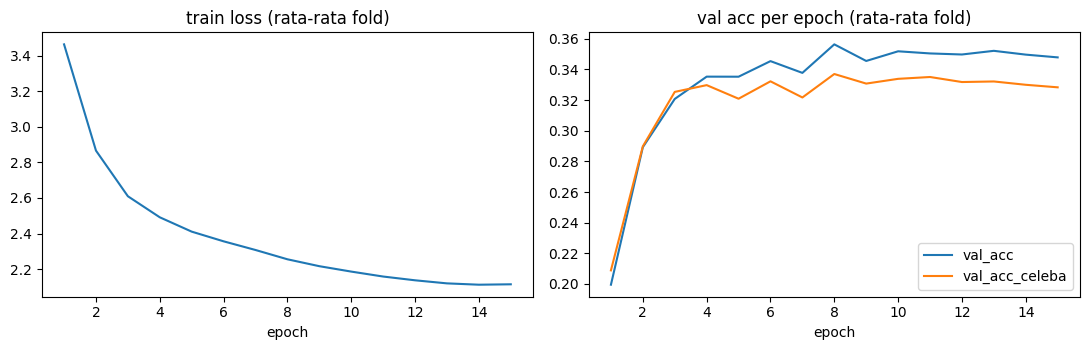

Jika val_acc_celeba memuncak jauh sebelum epoch terakhir lalu turun, kurangi FT_EPOCHS atau FT_LR_BACKBONE.


In [18]:
# ============================================================
# 7.2 FINE-TUNING K-FOLD (dengan cache per fold: aman dilanjutkan bila sesi terputus)
# ============================================================
globals().pop("frozen", None); gc.collect()          # embedding frozen sudah tersimpan; bebaskan memori GPU
if USE_AMP:
    torch.cuda.empty_cache()

ft_meta = json.dumps({"model": str(BACKBONE_LOCAL_DIR or BACKBONE_HF_ID), "img": FT_IMG_SIZE, "ep": FT_EPOCHS, "bs": FT_BATCH,
                      "lr": [FT_LR_HEAD, FT_LR_BACKBONE, FT_LLRD], "wd": FT_WD, "ls": FT_LABEL_SMOOTH, "drop": FT_DROPOUT,
                      "aux": FT_AUX_W, "folds": FOLD_HASH, "n": N_ALL, "input": FT_INPUT, "hold": int(len(hold_rows))}, sort_keys=True)

def ckpt_path(seed, k):
    return RESULT_DIR / f"ft_s{seed}_f{k}.pt"

oof_sum, test_sum, n_test_models, FT_HIST = np.zeros((len(train_rows), NUM_CLASSES)), np.zeros((len(test_rows), NUM_CLASSES)), 0, []
hold_sum = np.zeros((len(hold_rows), NUM_CLASSES))
t_start = time.time()
for seed in FT_SEEDS:
    for k, (tr, va) in enumerate(folds):
        cache = RESULT_DIR / f"ft_s{seed}_f{k}.npz"
        need_ckpt = FT_SAVE_CKPT and not ckpt_path(seed, k).exists()
        if cache.exists() and not RECOMPUTE and not need_ckpt:
            z = np.load(cache, allow_pickle=False)
            if str(z["meta"]) == ft_meta and np.array_equal(z["va"], va):
                oof_sum[va] += z["p_va"]; test_sum += z["p_te"]; hold_sum += z["p_ho"]; n_test_models += 1
                print(f"seed {seed} fold {k}: cache dipakai.")
                continue
        t0 = time.time()
        model, hist = train_one(train_rows[tr], train_rows[va], seed * 100 + k, f"s{seed}f{k}")
        p_va, p_te = predict_rows(model, train_rows[va]), predict_rows(model, test_rows)
        p_ho = predict_rows(model, hold_rows) if len(hold_rows) else np.zeros((0, NUM_CLASSES))
        np.savez_compressed(cache, va=va, p_va=p_va, p_te=p_te, p_ho=p_ho, meta=ft_meta)
        if FT_SAVE_CKPT:
            torch.save({n: (v.half() if v.is_floating_point() else v) for n, v in model.state_dict().items()}, ckpt_path(seed, k))
        oof_sum[va] += p_va; test_sum += p_te; hold_sum += p_ho; n_test_models += 1
        FT_HIST += hist
        print(f"seed {seed} fold {k}: selesai {(time.time() - t0) / 60:.1f} menit | acc fold (TTA) = {(p_va.argmax(1) == y12[va]).mean():.4f}")
        del model; gc.collect()
        if USE_AMP:
            torch.cuda.empty_cache()

COMP_OOF["ft"] = oof_sum / len(FT_SEEDS)
COMP_TEST["ft"] = test_sum / n_test_models
COMP_HOLD["ft"] = hold_sum / n_test_models
print(f"Fine-tuning total {(time.time() - t_start) / 60:.1f} menit.")

if FT_HIST:
    h = pd.DataFrame(FT_HIST).groupby("epoch")[["train_loss", "val_acc", "val_acc_celeba"]].mean()
    h.to_csv(RESULT_DIR / "E12_ft_history.csv")
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    h["train_loss"].plot(ax=ax[0], title="train loss (rata-rata fold)")
    h[["val_acc", "val_acc_celeba"]].plot(ax=ax[1], title="val acc per epoch (rata-rata fold)")
    plt.tight_layout(); plt.show()
    print("Jika val_acc_celeba memuncak jauh sebelum epoch terakhir lalu turun, kurangi FT_EPOCHS atau FT_LR_BACKBONE.")

## 8. Ensemble, XGBoost stacking, kalibrasi, dan aturan kepercayaan (semua dari OOF)

1. **Ensemble**: gabungan log-linear semua komponen; bobot dicari pada grid kasar dengan meminimalkan NLL OOF CelebA.
2. **XGBoost stacking**: XGBoost dilatih di atas prediksi OOF tiap komponen + fitur warna per region, dengan tuning parameter acak. Dipakai sebagai metode akhir **hanya bila** NLL OOF-nya lebih baik dari ensemble.
3. **Temperature scaling**: agar confidence sama dengan peluang benar.
4. **Ambang "yakin"**: confidence terendah yang masih memberi akurasi ≥ `TARGET_SELECTIVE_ACC`. Bila target tidak tercapai, tidak ada prediksi yang dilabeli "yakin".
5. **Himpunan kandidat konformal**: daftar sub-season yang memuat jawaban benar dengan peluang ≥ 1 − α.

In [19]:
# ============================================================
# 8.1 ENSEMBLE LOG-LINEAR: BOBOT + TEMPERATURE
# ============================================================
COMP_NAMES = list(COMP_OOF.keys())

def nll_of(p, y):
    return float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-12, 1)).mean())

def stack_features(comp, reg_rows, names):
    # masukan penggabung: log-probabilitas tiap komponen + fitur warna per region
    return np.hstack([np.log(np.clip(comp[n], 1e-6, 1.0)) for n in names] + [reg_rows]).astype(np.float32)

def final_predict(comp, reg_rows, cfg):
    # satu-satunya jalur dari prediksi komponen -> probabilitas akhir (dipakai OOF, holdout, test, dan inferensi)
    if cfg["method"] == "xgb_stack":
        raw = np.asarray(cfg["stacker"].predict_proba(stack_features(comp, reg_rows, cfg["comp_names"])), dtype=np.float64)
    else:
        raw = pool([apply_temperature(comp[n], cfg["comp_temps"][n]) for n in cfg["comp_names"]], cfg["ens_weights"])
    return apply_temperature(raw, cfg["temperature"])

# Tiap komponen dikalibrasi dulu dengan temperature sendiri. Tanpa ini, komponen yang akurat tetapi
# probabilitasnya terlalu "datar" (mis. LR dengan regularisasi kuat) akan kalah bobot secara tidak adil.
COMP_T = {n: fit_temperature(y12[cel], COMP_OOF[n][cel], lo=0.05, hi=10.0) for n in COMP_NAMES}
print("Temperature per komponen:", {n: round(t, 3) for n, t in COMP_T.items()})
oofs = [apply_temperature(COMP_OOF[n], COMP_T[n]) for n in COMP_NAMES]

steps = int(round(1 / ENS_STEP))
grid = [tuple(np.array(c) / steps) for c in itertools.product(range(steps + 1), repeat=len(COMP_NAMES)) if sum(c) == steps]
rows = []
for w in grid:
    p = pool([o[cel] for o in oofs], w)
    rows.append({**{f"w_{n}": wi for n, wi in zip(COMP_NAMES, w)}, "nll": nll_of(p, y12[cel]),
                 "acc": float((p.argmax(1) == y12[cel]).mean())})
ens_df = pd.DataFrame(rows).sort_values("nll").reset_index(drop=True)
display(ens_df.head(8).round(4))
ENS_W = tuple(float(ens_df.loc[0, f"w_{n}"]) for n in COMP_NAMES)
print("Bobot ensemble:", dict(zip(COMP_NAMES, ENS_W)))

p_oof_ens_raw = pool(oofs, ENS_W)
TEMP_ENS = fit_temperature(y12[cel], p_oof_ens_raw[cel])
p_oof_ens = apply_temperature(p_oof_ens_raw, TEMP_ENS)
ENS_CFG = {"method": "ensemble", "comp_names": COMP_NAMES, "comp_temps": COMP_T, "ens_weights": ENS_W, "temperature": TEMP_ENS, "stacker": None}
print(f"Temperature ensemble T = {TEMP_ENS:.3f} | NLL OOF CelebA = {nll_of(p_oof_ens[cel], y12[cel]):.4f}")

Temperature per komponen: {'emb_lr': 1.063, 'emb_lr_orig': 1.048, 'color_hgb': 1.322, 'ft': 1.118}


,w_emb_lr,w_emb_lr_orig,w_color_hgb,w_ft,nll,acc
0,0.1,0.0,0.3,0.6,1.8118,0.3485
1,0.0,0.0,0.3,0.7,1.8120,0.3479
2,0.0,0.1,0.3,0.6,1.8127,0.3536
3,0.0,0.0,0.4,0.6,1.8131,0.3496
4,0.1,0.0,0.4,0.5,1.8147,0.3435
5,0.1,0.0,0.2,0.7,1.8151,0.3429
6,0.2,0.0,0.3,0.5,1.8152,0.3479
7,0.1,0.1,0.3,0.5,1.8157,0.3502


Bobot ensemble: {'emb_lr': 0.1, 'emb_lr_orig': 0.0, 'color_hgb': 0.3, 'ft': 0.6}
Temperature ensemble T = 0.854 | NLL OOF CelebA = 1.8015


In [20]:
# ============================================================
# 8.2 XGBOOST STACKING (tuning acak) DAN PEMILIHAN METODE AKHIR
# ============================================================
# Penggabung XGBoost belajar dari prediksi OOF tiap komponen + fitur warna. Tiap kombinasi parameter dinilai
# dengan fold yang sama; jumlah pohon dipilih dari kurva NLL OOF (subset CelebA), bukan dari data test.
STACK_CFG, p_oof_stack, xgb_trials_df = None, None, None
if USE_XGB_STACK and xgb is not None:
    try:
        Z_tr = stack_features(COMP_OOF, X_reg[train_rows], COMP_NAMES)
        STACK_COLS = [f"logp[{n}]:{c}" for n in COMP_NAMES for c in class_names] + [REGION_COLS[i] for i in REG_KEEP]
        rng_x = np.random.default_rng(SEED)

        def sample_params(first):
            if first:                                 # titik awal yang konservatif
                return {"max_depth": 3, "learning_rate": 0.05, "subsample": 0.8, "colsample_bytree": 0.6,
                        "min_child_weight": 3.0, "reg_lambda": 5.0, "gamma": 0.0}
            return {"max_depth": int(rng_x.integers(2, 6)), "learning_rate": float(10 ** rng_x.uniform(-2.0, -0.8)),
                    "subsample": float(rng_x.uniform(0.6, 1.0)), "colsample_bytree": float(rng_x.uniform(0.3, 1.0)),
                    "min_child_weight": float(10 ** rng_x.uniform(0.0, 1.3)), "reg_lambda": float(10 ** rng_x.uniform(0.0, 2.0)),
                    "gamma": float(rng_x.uniform(0.0, 2.0))}

        def make_xgb(n_rounds, params):
            return xgb.XGBClassifier(n_estimators=int(n_rounds), objective="multi:softprob", eval_metric="mlogloss",
                                     tree_method="hist", random_state=SEED, n_jobs=XGB_NJOBS, **params)

        best, rows, t0 = None, [], time.time()
        for t in range(XGB_TRIALS):
            params = sample_params(t == 0)
            curve, models = np.zeros(XGB_MAX_ROUNDS), []
            for tr, va in folds:
                vc = va[cel[va]]                                  # dinilai pada baris CelebA di fold validasi
                m = make_xgb(XGB_MAX_ROUNDS, params)
                m.fit(Z_tr[tr], y12[tr], eval_set=[(Z_tr[vc], y12[vc])], verbose=False)
                curve += np.asarray(m.evals_result()["validation_0"]["mlogloss"], dtype=np.float64) * len(vc)
                models.append(m)
            curve /= float(cel.sum())
            n_best = int(np.argmin(curve)) + 1
            rows.append({"trial": t, **params, "n_rounds": n_best, "nll": float(curve[n_best - 1])})
            if best is None or curve[n_best - 1] < best["nll"]:
                best = {"nll": float(curve[n_best - 1]), "params": params, "n_rounds": n_best, "models": models}
        xgb_trials_df = pd.DataFrame(rows).sort_values("nll").reset_index(drop=True)
        display(xgb_trials_df.head(8).round(4))
        xgb_trials_df.to_csv(RESULT_DIR / "E12_xgb_trials.csv", index=False)
        print(f"Tuning XGBoost: {XGB_TRIALS} kombinasi dalam {(time.time() - t0) / 60:.1f} menit.")
        if best["n_rounds"] >= XGB_MAX_ROUNDS:
            print("CATATAN: jumlah pohon terbaik menyentuh XGB_MAX_ROUNDS; naikkan XGB_MAX_ROUNDS.")

        oof_stack = np.zeros((len(y12), NUM_CLASSES))
        for (tr, va), m in zip(folds, best["models"]):
            oof_stack[va] = m.predict_proba(Z_tr[va], iteration_range=(0, best["n_rounds"]))
        stacker = make_xgb(best["n_rounds"], best["params"]).fit(Z_tr, y12)
        TEMP_STACK = fit_temperature(y12[cel], oof_stack[cel])
        p_oof_stack = apply_temperature(oof_stack, TEMP_STACK)
        STACK_CFG = {"method": "xgb_stack", "comp_names": COMP_NAMES, "comp_temps": COMP_T, "ens_weights": ENS_W, "temperature": TEMP_STACK, "stacker": stacker}
        print(f"Temperature stacking T = {TEMP_STACK:.3f} | NLL OOF CelebA = {nll_of(p_oof_stack[cel], y12[cel]):.4f}")
        try:
            imp = pd.Series(stacker.feature_importances_, index=STACK_COLS).sort_values(ascending=False)
            print("Masukan paling berpengaruh di stacking:", {k: round(float(v), 4) for k, v in imp.head(10).items()})
        except Exception as e:
            print("(feature importance dilewati:", str(e)[:120], ")")
        del best
    except Exception as e:
        STACK_CFG, p_oof_stack = None, None
        print(f"XGBoost stacking GAGAL dan dilewati ({type(e).__name__}: {str(e)[:300]}). Metode akhir = ensemble.")
else:
    print("XGBoost stacking tidak dijalankan (USE_XGB_STACK=False atau xgboost tidak terpasang).")

nll_ens = nll_of(p_oof_ens[cel], y12[cel])
nll_stack = nll_of(p_oof_stack[cel], y12[cel]) if STACK_CFG is not None else float("inf")
FINAL_CFG = STACK_CFG if (STACK_CFG is not None and nll_stack < nll_ens - STACK_MIN_GAIN) else ENS_CFG
p_oof = p_oof_stack if FINAL_CFG["method"] == "xgb_stack" else p_oof_ens
TEMP = FINAL_CFG["temperature"]
print(f"\nNLL OOF | ensemble: {nll_ens:.4f} | xgb_stack: {nll_stack:.4f} -> METODE AKHIR: {FINAL_CFG['method']}"
      f" (stacking dipilih hanya bila lebih baik minimal {STACK_MIN_GAIN})")

table = {n: full_metrics(y12[cel], COMP_OOF[n][cel]) for n in COMP_NAMES}
table["ensemble"] = full_metrics(y12[cel], p_oof_ens[cel])
if STACK_CFG is not None:
    table["xgb_stack"] = full_metrics(y12[cel], p_oof_stack[cel])
oof_table = pd.DataFrame(table).T[SHOW + ["acc_at_50cov", "mean_conf"]]
display(oof_table.round(4))
oof_table.to_csv(RESULT_DIR / "E12_oof_celeba_components.csv")
print("OOF subset CelebA. Selisih di bawah ~2 poin antar baris masih dalam noise. Angka xgb_stack sedikit optimistis "
      "(parameter dan jumlah pohon dipilih di data yang sama); holdout di bagian 9 adalah pengujinya.")

,trial,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,reg_lambda,gamma,n_rounds,nll
0,15,3,0.0343,0.7524,0.5111,6.5973,5.2921,0.1753,183,1.8185
1,11,4,0.0469,0.7216,0.3216,3.6960,2.6864,0.8171,117,1.8186
2,6,3,0.0278,0.7878,0.4326,1.4754,8.9415,0.4538,207,1.8198
3,17,3,0.0725,0.7797,0.4906,1.3345,63.8565,0.9116,122,1.8245
4,13,2,0.0872,0.8657,0.5845,11.4347,2.1575,0.0454,76,1.8266
5,3,3,0.0340,0.6909,0.6882,1.2105,45.2129,1.2633,260,1.8273
6,0,3,0.0500,0.8000,0.6000,3.0000,5.0000,0.0000,117,1.8293
7,19,3,0.0330,0.8509,0.7089,6.9952,1.4753,0.8316,157,1.8294


Tuning XGBoost: 20 kombinasi dalam 24.1 menit.
Temperature stacking T = 1.029 | NLL OOF CelebA = 1.8181
Masukan paling berpengaruh di stacking: {'logp[emb_lr]:autunno_deep': 0.0359, 'logp[ft]:autunno_deep': 0.0317, 'logp[ft]:inverno_bright': 0.0311, 'logp[ft]:primavera_light': 0.0303, 'logp[ft]:inverno_deep': 0.0289, 'logp[color_hgb]:inverno_deep': 0.0283, 'logp[ft]:primavera_warm': 0.0255, 'logp[color_hgb]:primavera_light': 0.0217, 'logp[ft]:estate_light': 0.021, 'logp[ft]:autunno_warm': 0.0202}

NLL OOF | ensemble: 1.8015 | xgb_stack: 1.8181 -> METODE AKHIR: ensemble (stacking dipilih hanya bila lebih baik minimal 0.01)


,acc,macro_f1,top3,season_acc,undertone_acc,char_acc,nll,ece,auroc_conf,acc_at_20cov,acc_at_50cov,mean_conf
emb_lr,0.2788,0.2521,0.6228,0.5121,0.6661,0.4604,1.9582,0.0496,0.6266,0.4282,0.3465,0.3260
emb_lr_orig,0.2619,0.2297,0.6082,0.4767,0.6431,0.4531,2.0005,0.0500,0.6481,0.4169,0.3442,0.3101
color_hgb,0.3137,0.2901,0.6358,0.5402,0.6734,0.4834,1.9920,0.0997,0.6462,0.4930,0.4027,0.4134
ft,0.3266,0.3107,0.6959,0.5424,0.6717,0.5104,1.8506,0.0689,0.6438,0.4789,0.4218,0.3952
ensemble,0.3485,0.3305,0.7122,0.5593,0.6931,0.5245,1.8015,0.0343,0.6433,0.5070,0.4466,0.3756
xgb_stack,0.3479,0.3303,0.6942,0.5677,0.6970,0.5149,1.8181,0.0300,0.6411,0.5352,0.4432,0.3752


OOF subset CelebA. Selisih di bawah ~2 poin antar baris masih dalam noise. Angka xgb_stack sedikit optimistis (parameter dan jumlah pohon dipilih di data yang sama); holdout di bagian 9 adalah pengujinya.


In [21]:
# ============================================================
# 8.3 AMBANG "YAKIN" DAN HIMPUNAN KONFORMAL
# ============================================================
def selective_threshold(correct, conf, target, min_cov):
    cov, cacc, conf_sorted = risk_coverage(correct, conf)
    ok = np.where((cacc >= target) & (cov >= min_cov))[0]
    return (float(conf_sorted[ok.max()]), float(cov[ok.max()])) if len(ok) else (None, 0.0)

pc, yc = p_oof[cel], y12[cel]
corr_c, conf_c = pc.argmax(1) == yc, pc.max(1)
CONF_HIGH, cov_high = selective_threshold(corr_c, conf_c, TARGET_SELECTIVE_ACC, MIN_SELECTIVE_COVERAGE)
if CONF_HIGH is None:
    CONF_HIGH = 1.01                                  # > 1 = tidak ada prediksi yang dilabeli "yakin"
    print(f"TARGET_SELECTIVE_ACC={TARGET_SELECTIVE_ACC:.0%} TIDAK tercapai pada cakupan >= {MIN_SELECTIVE_COVERAGE:.0%}. "
          "Tidak ada prediksi yang dilabeli 'yakin'; platform selalu menampilkan kandidat.")
else:
    print(f"Ambang 'yakin' = {CONF_HIGH:.4f} -> akurasi >= {TARGET_SELECTIVE_ACC:.0%} pada {cov_high:.1%} gambar (OOF CelebA).")

cov, cacc, _ = risk_coverage(corr_c, conf_c)
rc = pd.DataFrame({"coverage": [0.05, 0.10, 0.20, 0.30, 0.50, 0.75, 1.00]})
rc["akurasi"] = [float(cacc[max(int(c * len(cacc)) - 1, 0)]) for c in rc["coverage"]]
display(rc.round(4).T)

def conformal_qhat(y, p, alpha):
    s = 1.0 - p[np.arange(len(y)), y]
    n = len(s)
    return float(np.quantile(s, min(1.0, math.ceil((n + 1) * (1 - alpha)) / n), method="higher"))

def conformal_sets(p, qhat):
    S = p >= (1.0 - qhat)
    S[np.arange(len(p)), p.argmax(1)] = True          # prediksi teratas selalu masuk
    return S

def set_report(y, p, qhat):
    S = conformal_sets(p, qhat)
    size = S.sum(1)
    single = size == 1
    return {"cakupan": float(S[np.arange(len(y)), y].mean()), "ukuran_rata2": float(size.mean()),
            "ukuran_median": float(np.median(size)), "frac_1_kelas": float(single.mean()),
            "akurasi_bila_1_kelas": float((p.argmax(1)[single] == y[single]).mean()) if single.any() else float("nan"),
            "frac_<=3_kelas": float((size <= 3).mean())}

QHAT = {a: conformal_qhat(yc, pc, a) for a in CONFORMAL_ALPHAS}
display(pd.DataFrame({f"target {1 - a:.0%}": set_report(yc, pc, q) for a, q in QHAT.items()}).T.round(4))
print("Tabel di atas dihitung pada data kalibrasi yang sama (OOF), jadi cakupannya pasti ~target. Uji sebenarnya ada di bagian 9.")

Ambang 'yakin' = 0.4139 -> akurasi >= 50% pada 34.5% gambar (OOF CelebA).


,0,1,2,3,4,5,6
coverage,0.0500,0.1000,0.200,0.3000,0.5000,0.7500,1.0000
akurasi,0.6364,0.5819,0.507,0.4972,0.4466,0.3861,0.3485


,cakupan,ukuran_rata2,ukuran_median,frac_1_kelas,akurasi_bila_1_kelas,frac_<=3_kelas
target 90%,0.9005,5.4761,5.0,0.0006,1.00,0.1602
target 80%,0.8004,3.9562,4.0,0.0045,0.75,0.3924


Tabel di atas dihitung pada data kalibrasi yang sama (OOF), jadi cakupannya pasti ~target. Uji sebenarnya ada di bagian 9.


## 9. Holdout baru dan official test — label dipakai mulai di sini

- **Holdout**: belum pernah dipakai di eksperimen mana pun. Ini perkiraan paling jujur untuk kinerja pada gambar CelebA baru.
- **Official test**: dipakai untuk membandingkan dengan E10 dan FaRL (angka mereka dihitung di sini), tetapi sudah dipakai berulang sejak E1.

Bila angka holdout jauh di bawah official test, artinya pilihan-pilihan sebelumnya sudah "menyesuaikan diri" dengan official test.

In [22]:
# ============================================================
# 9.1 METRIK HOLDOUT DAN TEST + INTERVAL KEPERCAYAAN BOOTSTRAP
# ============================================================
def variants(comp, reg_rows):
    out = {n: comp[n] for n in COMP_NAMES}
    out["ensemble"] = final_predict(comp, reg_rows, ENS_CFG)
    if STACK_CFG is not None:
        out["xgb_stack"] = final_predict(comp, reg_rows, STACK_CFG)
    return out

def bootstrap_ci(y, p, seed=SEED):
    rng = np.random.default_rng(seed)
    pred, m = p.argmax(1), full_metrics(y, p)
    ok, top3 = pred == y, (np.argsort(-p, axis=1)[:, :3] == y[:, None]).any(1)
    boot = {"acc": [], "macro_f1": [], "top3": []}
    for _ in range(N_BOOT):
        ix = rng.integers(0, len(y), len(y))
        boot["acc"].append(ok[ix].mean())
        boot["macro_f1"].append(sk_f1_score(y[ix], pred[ix], average="macro", labels=list(range(NUM_CLASSES)), zero_division=0))
        boot["top3"].append(top3[ix].mean())
    return pd.DataFrame({k: {"nilai": m[k], "ci95_lo": np.percentile(v, 2.5), "ci95_hi": np.percentile(v, 97.5)} for k, v in boot.items()}).T

COLS = SHOW + ["top2", "acc_at_50cov", "worst3_recall", "mean_conf"]
FINAL_NAME = FINAL_CFG["method"]
maj = lambda v: float(np.bincount(v).max() / len(v))
print("Metode akhir:", FINAL_NAME)

# ---------- Holdout baru ----------
hold_m, p_hold = None, None
if len(hold_rows):
    var_ho = variants(COMP_HOLD, X_reg[hold_rows])
    p_hold = var_ho[FINAL_NAME]
    hold_table = pd.DataFrame({n: full_metrics(yho, p) for n, p in var_ho.items()}).T
    hold_m = hold_table.loc[FINAL_NAME].to_dict()
    print(f"\n=== HOLDOUT BARU ({len(hold_rows)} gambar CelebA, tidak pernah dipakai) ===")
    display(hold_table[COLS].round(4))
    hold_table.to_csv(RESULT_DIR / "E12_holdout_metrics.csv")
    display(bootstrap_ci(yho, p_hold).round(4))
    print(f"Baseline tebak-mayoritas di holdout | 12 kelas: {maj(yho):.3f} | season: {maj(season_of[yho]):.3f}")
else:
    print("Holdout tidak dipakai (HOLDOUT_FRAC = 0).")

# ---------- Official test ----------
var_te = variants(COMP_TEST, X_reg[test_rows])
p_test = var_te[FINAL_NAME]
table = {n: full_metrics(yte, p) for n, p in var_te.items()}
test_table = pd.concat([pd.DataFrame(table).T, pd.DataFrame(REFERENCE).T])
print(f"\n=== OFFICIAL TEST ({len(test_rows)} gambar) ===")
display(test_table[COLS].round(4))
test_table.to_csv(RESULT_DIR / "E12_test_metrics.csv")
test_m = table[FINAL_NAME]
print(f"Baseline tebak-mayoritas di test | 12 kelas: {maj(yte):.3f} | season: {maj(season_of[yte]):.3f} | "
      f"undertone: {maj(warm_of[yte]):.3f} | karakteristik: {maj(char_of[yte]):.3f}")

ci = bootstrap_ci(yte, p_test)
display(ci.round(4))
if SMOKE_TEST:
    print("SMOKE_TEST: perbandingan dengan E10 / FaRL dilewati (subset kecil dan 1 epoch, angkanya tidak sebanding).")
else:
    for name, ref in REFERENCE.items():
        lo, hi = ci.loc["acc", "ci95_lo"], ci.loc["acc", "ci95_hi"]
        verdict = "di atas (di luar CI)" if ref["acc"] < lo else ("di bawah (di luar CI)" if ref["acc"] > hi else "TIDAK berbeda nyata (di dalam CI)")
        print(f"Akurasi E12 {test_m['acc']:.4f} vs {name} {ref['acc']:.4f}: {verdict}")

rng = np.random.default_rng(SEED)
pred_e = p_test.argmax(1)
ens_ok = pred_e == yte
others = {n: p.argmax(1) == yte for n, p in var_te.items() if n != FINAL_NAME}
diffs = {n: [] for n in others}
for _ in range(N_BOOT):
    ix = rng.integers(0, len(yte), len(yte))
    for n in others:
        diffs[n].append(ens_ok[ix].mean() - others[n][ix].mean())
dd = pd.DataFrame({n: {"selisih_acc": np.mean(v), "ci95_lo": np.percentile(v, 2.5), "ci95_hi": np.percentile(v, 97.5)} for n, v in diffs.items()}).T
display(dd.round(4))
print(f"Tabel terakhir: {FINAL_NAME} dikurangi tiap baris (bootstrap berpasangan). CI yang memuat 0 = baris itu setara dengan metode akhir.\n"
      "Untuk deployment di server kecil, pilih baris paling ringan yang masih setara.")

Metode akhir: ensemble

=== HOLDOUT BARU (290 gambar CelebA, tidak pernah dipakai) ===


,acc,macro_f1,top3,season_acc,undertone_acc,char_acc,nll,ece,auroc_conf,acc_at_20cov,top2,acc_at_50cov,worst3_recall,mean_conf
emb_lr,0.2621,0.2430,0.6207,0.5310,0.6586,0.4483,1.9714,0.0721,0.6343,0.4655,0.4655,0.3310,0.1223,0.3251
emb_lr_orig,0.2483,0.2340,0.6034,0.4793,0.6552,0.4172,2.0243,0.0644,0.6451,0.3793,0.4207,0.3241,0.0643,0.3090
color_hgb,0.2690,0.2628,0.6345,0.5172,0.6483,0.4414,2.0554,0.1476,0.5616,0.3103,0.5000,0.2966,0.1595,0.4158
ft,0.2759,0.2546,0.6828,0.5448,0.6759,0.4379,1.8647,0.1050,0.6513,0.3966,0.5586,0.3655,0.1258,0.3790
ensemble,0.2862,0.2729,0.6897,0.5483,0.6931,0.4793,1.8291,0.0794,0.6374,0.4310,0.5379,0.3724,0.1467,0.3638
xgb_stack,0.3034,0.2826,0.6966,0.5793,0.7034,0.4759,1.8398,0.0730,0.5840,0.3966,0.6069,0.3586,0.1516,0.3655


,nilai,ci95_lo,ci95_hi
acc,0.2862,0.2345,0.3379
macro_f1,0.2729,0.2165,0.3208
top3,0.6897,0.6345,0.7415


Baseline tebak-mayoritas di holdout | 12 kelas: 0.117 | season: 0.272

=== OFFICIAL TEST (912 gambar) ===


,acc,macro_f1,top3,season_acc,undertone_acc,char_acc,nll,ece,auroc_conf,acc_at_20cov,top2,acc_at_50cov,worst3_recall,mean_conf
emb_lr,0.2971,0.2623,0.6469,0.5395,0.6765,0.4792,1.8973,0.0478,0.6504,0.4451,0.5143,0.4057,0.0815,0.3306
emb_lr_orig,0.2741,0.2376,0.6294,0.5428,0.6776,0.4550,1.9421,0.0392,0.6861,0.4505,0.4715,0.3860,0.0577,0.3131
color_hgb,0.3125,0.2869,0.6425,0.5537,0.6996,0.4836,1.9770,0.1064,0.6184,0.4176,0.5274,0.3772,0.1752,0.4175
ft,0.3487,0.3241,0.7029,0.5811,0.6985,0.4956,1.8000,0.0377,0.6309,0.5110,0.5855,0.4386,0.1568,0.3800
ensemble,0.3542,0.3232,0.7193,0.5811,0.7094,0.5164,1.7653,0.0400,0.6222,0.4890,0.6031,0.4386,0.1522,0.3653
xgb_stack,0.3520,0.3249,0.7061,0.5965,0.7018,0.5154,1.7758,0.0421,0.6375,0.4835,0.5954,0.4518,0.1717,0.3714
E10 (frozen DINOv3 + LR),0.2939,0.2618,0.6436,0.5274,NaN,NaN,NaN,NaN,0.6530,NaN,NaN,NaN,NaN,NaN
FaRL16_E6,0.3246,0.2947,0.6579,0.5263,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Baseline tebak-mayoritas di test | 12 kelas: 0.128 | season: 0.289 | undertone: 0.507 | karakteristik: 0.251


,nilai,ci95_lo,ci95_hi
acc,0.3542,0.3235,0.3838
macro_f1,0.3232,0.2930,0.3516
top3,0.7193,0.6897,0.7489


Akurasi E12 0.3542 vs E10 (frozen DINOv3 + LR) 0.2939: di atas (di luar CI)
Akurasi E12 0.3542 vs FaRL16_E6 0.3246: TIDAK berbeda nyata (di dalam CI)


,selisih_acc,ci95_lo,ci95_hi
emb_lr,0.0572,0.0274,0.0877
emb_lr_orig,0.0805,0.0515,0.1107
color_hgb,0.0416,0.0110,0.0724
ft,0.0059,-0.0154,0.0285
xgb_stack,0.0025,-0.0241,0.0274


Tabel terakhir: ensemble dikurangi tiap baris (bootstrap berpasangan). CI yang memuat 0 = baris itu setara dengan metode akhir.
Untuk deployment di server kecil, pilih baris paling ringan yang masih setara.



--- HOLDOUT BARU ---
  Ambang 'yakin' (dari OOF) = 0.4139
  yakin            : n=  96 (33.1%) akurasi=0.4062
  perlu konfirmasi : n= 194 (66.9%) akurasi top-1=0.2268


,cakupan,ukuran_rata2,ukuran_median,frac_1_kelas,akurasi_bila_1_kelas,frac_<=3_kelas
target 90%,0.9241,5.6034,6.0,0.0,NaN,0.1379
target 80%,0.8138,4.0172,4.0,0.0,NaN,0.3862



--- OFFICIAL TEST ---
  Ambang 'yakin' (dari OOF) = 0.4139
  yakin            : n= 293 (32.1%) akurasi=0.4812
  perlu konfirmasi : n= 619 (67.9%) akurasi top-1=0.2940


,cakupan,ukuran_rata2,ukuran_median,frac_1_kelas,akurasi_bila_1_kelas,frac_<=3_kelas
target 90%,0.9079,5.5186,6.0,0.0000,NaN,0.1524
target 80%,0.8235,4.0417,4.0,0.0033,0.6667,0.3684


'cakupan' harus mendekati target. 'ukuran_rata2' = berapa sub-season yang harus ditampilkan ke pengguna agar cakupan itu tercapai.


,class,support,precision,recall,f1,conf_when_correct,conf_when_wrong,conf_gap
0,primavera_bright,66,0.200,0.106,0.139,0.302,0.343,-0.041
1,estate_soft,63,0.209,0.143,0.170,0.354,0.282,0.071
2,estate_cool,53,0.180,0.208,0.193,0.296,0.341,-0.045
3,autunno_soft,73,0.198,0.219,0.208,0.312,0.318,-0.006
4,inverno_cool,89,0.299,0.292,0.295,0.372,0.354,0.018
5,primavera_warm,73,0.328,0.301,0.314,0.385,0.298,0.087
6,estate_light,70,0.462,0.343,0.393,0.367,0.367,-0.000
7,inverno_bright,58,0.370,0.345,0.357,0.465,0.368,0.097
8,autunno_warm,74,0.441,0.351,0.391,0.353,0.336,0.017
9,autunno_deep,112,0.524,0.482,0.502,0.431,0.431,0.000


Kelas dengan conf_gap <= 0 (confidence tidak informatif): 4 dari 12 (E10: 6).


,actual,predicted,count,same_season,same_undertone
0,autunno_deep,inverno_deep,39,False,False
1,inverno_cool,inverno_deep,33,True,True
2,estate_light,primavera_light,21,False,False
3,inverno_deep,inverno_cool,19,True,True
4,inverno_deep,autunno_deep,15,False,False
5,primavera_warm,autunno_warm,12,False,True
6,inverno_bright,estate_cool,12,False,True
7,estate_soft,autunno_soft,12,False,False
8,primavera_light,estate_light,12,False,False
9,inverno_bright,inverno_deep,11,True,True


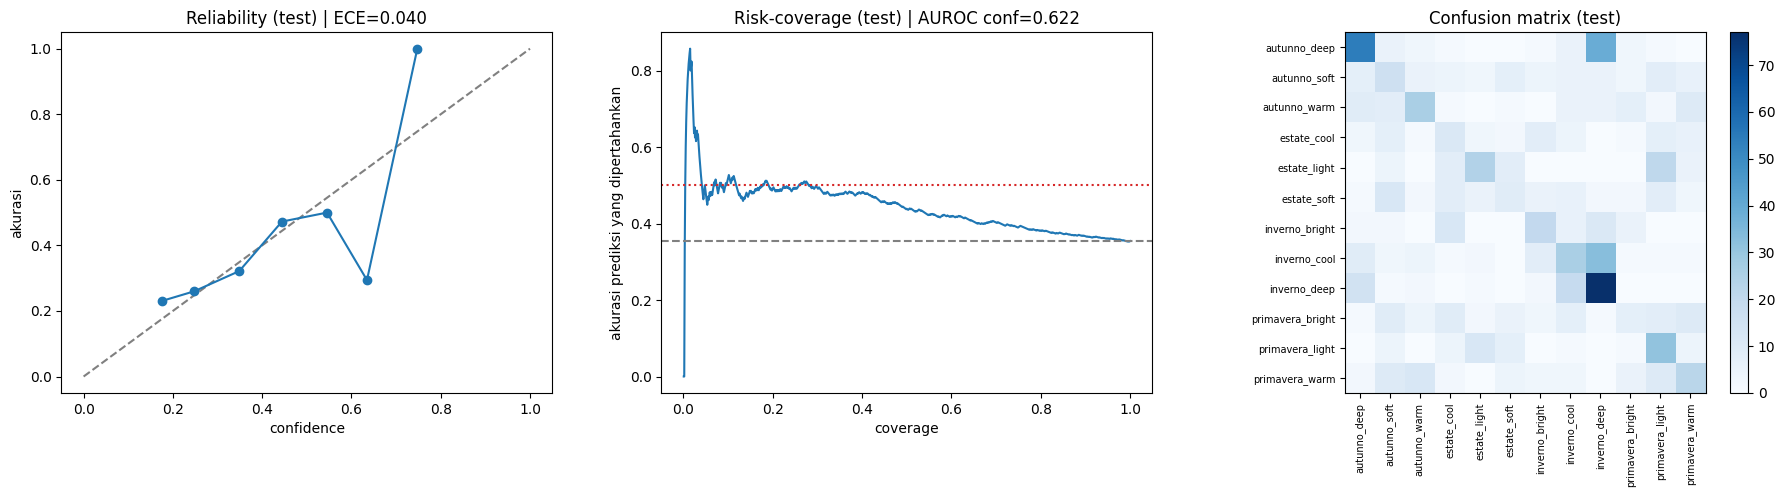

In [23]:
# ============================================================
# 9.2 KEPERCAYAAN: AMBANG 'YAKIN' DAN HIMPUNAN KONFORMAL (holdout dan test)
# ============================================================
def confidence_report(name, y, p):
    conf, ok = p.max(1), p.argmax(1) == y
    hi = conf >= CONF_HIGH
    print(f"\n--- {name} ---")
    if CONF_HIGH > 1.0:
        print("  Tidak ada prediksi berlabel 'yakin' (target akurasi tidak tercapai di OOF); semua keluaran berupa kandidat.")
    else:
        print(f"  Ambang 'yakin' (dari OOF) = {CONF_HIGH:.4f}")
        print(f"  yakin            : n={int(hi.sum()):4d} ({hi.mean():.1%}) akurasi={(ok[hi].mean() if hi.any() else float('nan')):.4f}")
        print(f"  perlu konfirmasi : n={int((~hi).sum()):4d} ({(~hi).mean():.1%}) akurasi top-1={(ok[~hi].mean() if (~hi).any() else float('nan')):.4f}")
    t = pd.DataFrame({f"target {1 - a:.0%}": set_report(y, p, q) for a, q in QHAT.items()}).T
    display(t.round(4))
    return t

if p_hold is not None:
    confidence_report("HOLDOUT BARU", yho, p_hold).to_csv(RESULT_DIR / "E12_holdout_conformal.csv")
conf_te = p_test.max(1)
conf_table = confidence_report("OFFICIAL TEST", yte, p_test)
conf_table.to_csv(RESULT_DIR / "E12_test_conformal.csv")
print("'cakupan' harus mendekati target. 'ukuran_rata2' = berapa sub-season yang harus ditampilkan ke pengguna agar cakupan itu tercapai.")
prec, rec, f1c, sup = precision_recall_fscore_support(yte, pred_e, labels=list(range(NUM_CLASSES)), zero_division=0)
rows = []
for c, name in enumerate(class_names):
    t = yte == c
    okc, bad = t & (pred_e == c), t & (pred_e != c)
    rows.append({"class": name, "support": int(t.sum()), "precision": prec[c], "recall": rec[c], "f1": f1c[c],
                 "conf_when_correct": conf_te[okc].mean() if okc.any() else np.nan,
                 "conf_when_wrong": conf_te[bad].mean() if bad.any() else np.nan})
per_class_df = pd.DataFrame(rows).sort_values("recall").reset_index(drop=True)
per_class_df["conf_gap"] = per_class_df["conf_when_correct"] - per_class_df["conf_when_wrong"]
display(per_class_df.round(3))
per_class_df.to_csv(RESULT_DIR / "E12_test_per_subseason.csv", index=False)
print(f"Kelas dengan conf_gap <= 0 (confidence tidak informatif): {int((per_class_df['conf_gap'] <= 0).sum())} dari {NUM_CLASSES} (E10: 6).")

cm = confusion_matrix(yte, pred_e, labels=list(range(NUM_CLASSES)))
pairs = [{"actual": idx2class[i], "predicted": idx2class[j], "count": int(cm[i, j]),
          "same_season": bool(season_of[i] == season_of[j]), "same_undertone": bool(warm_of[i] == warm_of[j])}
         for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
if pairs:
    display(pd.DataFrame(pairs).sort_values("count", ascending=False).head(12).reset_index(drop=True))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
edges = np.linspace(0, 1, 11)
xs, ys = [], []
for i in range(10):
    m = (conf_te >= edges[i]) & (conf_te < edges[i + 1] if i < 9 else conf_te <= edges[i + 1])
    if m.sum() >= 5:
        xs.append(conf_te[m].mean()); ys.append(ens_ok[m].mean())
axes[0].plot([0, 1], [0, 1], "--", color="gray"); axes[0].plot(xs, ys, "o-")
axes[0].set_xlabel("confidence"); axes[0].set_ylabel("akurasi"); axes[0].set_title(f"Reliability (test) | ECE={test_m['ece']:.3f}")
cov, cacc, _ = risk_coverage(ens_ok, conf_te)
axes[1].plot(cov, cacc); axes[1].axhline(ens_ok.mean(), ls="--", color="gray")
axes[1].axhline(TARGET_SELECTIVE_ACC, ls=":", color="tab:red")
axes[1].set_xlabel("coverage"); axes[1].set_ylabel("akurasi prediksi yang dipertahankan")
axes[1].set_title(f"Risk-coverage (test) | AUROC conf={test_m['auroc_conf']:.3f}")
im = axes[2].imshow(cm, cmap="Blues")
axes[2].set_xticks(range(NUM_CLASSES)); axes[2].set_yticks(range(NUM_CLASSES))
axes[2].set_xticklabels(class_names, rotation=90, fontsize=7); axes[2].set_yticklabels(class_names, fontsize=7)
axes[2].set_title("Confusion matrix (test)"); plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout(); plt.savefig(RESULT_DIR / "E12_test_diagnostics.png", dpi=130); plt.show()

## 10. Ekspor artefak dan inferensi satu gambar

Jalur inferensi satu gambar memakai fungsi yang sama dengan jalur batch. Gambar masukan harus sudah **masked** dengan cara yang sama seperti dataset (latar hitam, wajah + rambut). Mask biner dan foto asli bersifat opsional kecuali model akhir memakai komponen RGB asli.

In [24]:
# ============================================================
# 10.1 SIMPAN ARTEFAK
# ============================================================
artifacts = {
    "experiment_id": EXPERIMENT_ID, "class_names": class_names, "season_names": season_names, "char_names": char_names,
    "season_of": season_of, "char_of": char_of, "warm_of": warm_of,
    **FINAL_CFG,                                   # method, comp_names, comp_temps, ens_weights, temperature, stacker
    "conf_high": CONF_HIGH, "conformal_qhat": QHAT,
    "models": COMP_MODEL, "emb_keys": EMB_KEYS, "C": BEST_C,
    "region_cols": REGION_COLS, "reg_keep": REG_KEEP, "region_parts": REGION_PARTS, "region_min_pix": REGION_MIN_PIX,
    "backbone": str(BACKBONE_LOCAL_DIR or BACKBONE_HF_ID), "parser": str(PARSER_LOCAL_DIR or PARSER_HF_ID),
    "parse_size": PARSE_SIZE, "cache_size": CACHE_SIZE, "emb_img_size": EMB_IMG_SIZE, "ft_img_size": FT_IMG_SIZE,
    "extra_mean_layers": EXTRA_MEAN_LAYERS, "mask_thresh": MASK_THRESH, "mask_used": bool(MASK_OK), "ft_input": FT_INPUT,
    "ft_ckpts": [f"ft_s{s}_f{k}.pt" for s in FT_SEEDS for k in range(N_FOLDS)], "ft_dropout": FT_DROPOUT,
}
ART_PATH = RESULT_DIR / "E12_artifacts.joblib"
dump(artifacts, ART_PATH)

S_main = conformal_sets(p_test, QHAT[CONFORMAL_ALPHAS[0]])
pd.DataFrame({
    "path": df["resolved_path"].astype(str).to_numpy()[test_rows],
    "true": [idx2class[i] for i in yte], "pred": [idx2class[i] for i in pred_e],
    "confidence": conf_te, "yakin": conf_te >= CONF_HIGH,
    "kandidat": ["|".join(class_names[j] for j in np.where(r)[0][np.argsort(-p_test[i][np.where(r)[0]])]) for i, r in enumerate(S_main)],
}).to_csv(RESULT_DIR / "E12_test_predictions.csv", index=False)

summary = {"experiment_id": EXPERIMENT_ID, "smoke_test": SMOKE_TEST, "final_method": FINAL_CFG["method"],
           "comp_names": COMP_NAMES, "ens_weights": dict(zip(COMP_NAMES, ENS_W)), "comp_temps": COMP_T, "temperature": TEMP,
           "conf_high": CONF_HIGH, "conformal_qhat": {str(a): q for a, q in QHAT.items()},
           "dup_threshold": DUP_THR, "C": BEST_C, "mask_used": bool(MASK_OK), "original_rgb_used": bool(EMB_ORIG is not None),
           "ft_input": FT_INPUT, "n_dev": int(len(train_rows)), "n_holdout": int(len(hold_rows)),
           "holdout_metrics": hold_m, "test_metrics": test_m, "reference": REFERENCE}
(RESULT_DIR / "E12_summary.json").write_text(json.dumps(summary, indent=2, default=float))
print("Tersimpan di", RESULT_DIR)

Tersimpan di /kaggle/working/E12


In [25]:
# ============================================================
# 10.2 INFERENSI SATU GAMBAR + UJI KONSISTENSI DENGAN JALUR BATCH
# ============================================================
def load_ft_models(art):
    models = []
    for name in art["ft_ckpts"]:
        path = RESULT_DIR / name
        if not path.exists():
            return None
        m = ArmoNet(load_backbone().float())
        m.load_state_dict(torch.load(path, map_location="cpu"))
        models.append(m.float().to(DEVICE).eval())
    return models

@torch.no_grad()
def predict_masked_image(path, art, ft_models, mask_path=None, orig_path=None):
    # path = gambar ber-masking (latar hitam). mask_path = mask biner (opsional). orig_path = foto asli (wajib bila
    # model memakai komponen RGB asli).
    names = art["comp_names"]
    needs_orig = ("emb_lr_orig" in names) or ("ft" in names and art["ft_input"] == "original")
    if needs_orig and orig_path is None:
        raise ValueError("Model ini memakai komponen RGB asli: berikan orig_path.")
    big, small, valid, small_o = load_squares(path, mask_path, orig_path)
    label_map = parse_u8(torch.from_numpy(big)[None])[0]
    reg = region_color_features(big, label_map, REGION_IDS, GLASSES_IDS, valid)[None, :]
    reg_keep = reg[:, art["reg_keep"]].astype(np.float64)
    comp = {}
    if "emb_lr" in names:
        e = embed_u8(small[None])
        comp["emb_lr"] = proba_full(art["models"]["emb_lr"], np.hstack([e[k] for k in art["emb_keys"]]).astype(np.float64))
    if "emb_lr_orig" in names:
        e = embed_u8(small_o[None])
        comp["emb_lr_orig"] = proba_full(art["models"]["emb_lr_orig"], np.hstack([e[k] for k in art["emb_keys"]]).astype(np.float64))
    if "color_hgb" in names:
        comp["color_hgb"] = proba_full(art["models"]["color_hgb"], reg_keep)
    if "ft" in names:
        x = eval_tf(Image.fromarray(small_o if art["ft_input"] == "original" else small)).unsqueeze(0).to(DEVICE)
        ps = []
        for m in ft_models:
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                ps.append(((m(x)[0].float().softmax(1) + m(torch.flip(x, dims=[3]))[0].float().softmax(1)) / 2).cpu().numpy())
        comp["ft"] = np.mean(ps, axis=0).astype(np.float64)
    p = final_predict(comp, reg_keep, art)[0]
    order = np.argsort(-p)
    qhat = art["conformal_qhat"][min(art["conformal_qhat"])]
    cand = [int(i) for i in order if p[i] >= 1 - qhat]
    if int(order[0]) not in cand:
        cand = [int(order[0])] + cand
    return {"sub_season": art["class_names"][int(order[0])], "confidence": float(p[order[0]]),
            "status": "yakin" if p[order[0]] >= art["conf_high"] else "perlu_konfirmasi",
            "kandidat": [(art["class_names"][i], float(p[i])) for i in cand],
            "undertone": "hangat" if p[art["warm_of"] == 1].sum() >= 0.5 else "dingin",
            "p_undertone_hangat": float(p[art["warm_of"] == 1].sum()), "probs": p}

art = load(ART_PATH)
frozen = load_backbone().float().to(DEVICE).eval()          # dipakai embed_u8
ft_models = load_ft_models(art)
if ft_models is None:
    print("Checkpoint fine-tuning tidak ada (FT_SAVE_CKPT=False atau cache lama) -> uji konsistensi dilewati.")
else:
    for i in range(3):
        r = test_rows[i]
        out = predict_masked_image(str(df["resolved_path"].iloc[r]), art, ft_models,
                                   mask_path=str(df["mask_path"].iloc[r]) if art["mask_used"] else None,
                                   orig_path=str(df["orig_path"].iloc[r]) if HAS_ORIG else None)
        diff = float(np.abs(out["probs"] - p_test[i]).max())
        print(f"[{i}] true={idx2class[int(yte[i])]:17s} pred={out['sub_season']:17s} conf={out['confidence']:.3f} "
              f"{out['status']:16s} kandidat={[c for c, _ in out['kandidat']]} | max|beda dgn batch|={diff:.2e}")
        assert diff < 2e-2, "Jalur inferensi tidak konsisten dengan jalur batch."
    print("Uji konsistensi inferensi: PASS")

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[0] true=autunno_deep      pred=inverno_deep      conf=0.406 perlu_konfirmasi kandidat=['inverno_deep', 'autunno_deep', 'autunno_warm', 'autunno_soft'] | max|beda dgn batch|=8.47e-05
[1] true=autunno_deep      pred=inverno_deep      conf=0.308 perlu_konfirmasi kandidat=['inverno_deep', 'autunno_soft', 'autunno_deep', 'estate_cool', 'estate_soft', 'inverno_cool', 'primavera_light'] | max|beda dgn batch|=8.67e-05
[2] true=autunno_deep      pred=autunno_deep      conf=0.460 yakin            kandidat=['autunno_deep', 'inverno_deep', 'autunno_warm', 'inverno_cool'] | max|beda dgn batch|=2.32e-04
Uji konsistensi inferensi: PASS


## Cara membaca hasil

**Urutan pemeriksaan**

1. **Cek mask (3.2)**: apakah mask biner sejajar dengan RGB-M. Bila tidak, notebook otomatis kembali ke cara E11.
2. **Visual parsing (3.4)**: label region harus pas di wajah; baris RGB asli harus orang yang sama.
3. **Tabel AUROC fitur (3.5)**: seberapa kuat warna per region memisahkan undertone. AUROC ~0,5–0,6 berarti sinyalnya lemah.
4. **Grup per orang (5.1, 5.2)**: periksa contoh pasangan near-duplicate, daftar nama dengan foto terbanyak, dan jumlah orang dengan lebih dari satu label.
5. **Tabel komponen (6.2)**: bandingkan `emb_lr` (RGB-M) dengan `emb_lr_orig` (RGB asli). Ini menjawab apakah masking membantu atau justru memberi jalan pintas.
6. **Kurva val per epoch (7.2)**: untuk menyetel `FT_EPOCHS` dan `FT_LR_BACKBONE`.
7. **Ensemble vs XGBoost stacking (8.1, 8.2)**: metode akhir dipilih otomatis dari NLL OOF.
8. **Holdout dan test (9.1)**: angka holdout adalah yang dilaporkan sebagai kinerja; official test untuk perbandingan dengan E10 / FaRL.
9. **Kepercayaan (9.2)**: `ukuran_rata2` himpunan kandidat menunjukkan berapa sub-season yang realistis ditampilkan ke pengguna.

**Aturan keluaran untuk platform**

- `status = yakin` → tampilkan satu sub-season.
- `status = perlu_konfirmasi` → tampilkan `kandidat` dan minta konfirmasi pengguna (pertanyaan singkat atau foto kedua).
- Jangan menampilkan confidence mentah sebagai "akurasi".

**Catatan untuk deployment (server tanpa GPU, RAM 4 GB)**

- Model akhir di sini memuat parser, satu backbone frozen, dan `N_FOLDS × len(FT_SEEDS)` model fine-tuned. Itu terlalu berat untuk server kecil.
- Lihat tabel selisih di 9.1: bila komponen tunggal atau gabungan tanpa `ft` setara dengan metode akhir, pakai yang ringan.
- Bila `ft` memang menyumbang, latih ulang **satu** model fine-tuned di seluruh data pengembangan untuk deployment.

**Keterbatasan yang perlu disebut di laporan**

- Identitas CelebA tidak tersedia; pengelompokan CelebA hanya dari near-duplicate.
- Prediksi `ft` di holdout/test adalah rata-rata semua model fold, sedangkan kalibrasi memakai prediksi satu model per fold.
- Gambar produksi (kamera HP) berbeda dari dataset selebriti; angka di sini belum tentu berlaku di sana.

In [26]:
# ============================================================
# 11. CATAT HASIL KE modellab_registry (hanya run penuh)
# ============================================================
_prec, _rec, _, _ = precision_recall_fscore_support(yte, pred_e, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)
final_metrics = {**test_m, "macro_precision": float(_prec), "macro_recall": float(_rec)}
if hold_m is not None:
    final_metrics.update({f"holdout_{k}": hold_m[k] for k in ["acc", "macro_f1", "top3", "season_acc"]})
print({k: round(float(v), 4) for k, v in final_metrics.items() if k in ("acc", "macro_f1", "macro_precision", "macro_recall", "top3", "holdout_acc")})

if LOG_TO_REGISTRY:
    import modellab_registry

    # Nama variabel di bawah dipertahankan seperti sel aslinya karena registry membaca globals().
    # `f1_score` aman ditimpa: fungsi sklearn diimpor dengan nama `sk_f1_score` di sel 1.
    accuracy = final_metrics["acc"]
    f1_score = final_metrics["macro_f1"]
    precision = final_metrics["macro_precision"]
    recall = final_metrics["macro_recall"]

    modellab_registry.auto_log_experiment(
        env_globals=globals(),
        topic="topic-a",
        model="DINOv3 ViT",
        objective="E12: fine-tuning DINOv3 ViT + warna Lab per region, grup per orang, holdout baru, XGBoost stacking",
        dataset="deep_armocromia",
        owner="Fatih Itsbatul Haq"
    )
else:
    print("SMOKE_TEST aktif: hasil tidak dicatat ke modellab_registry.")

{'acc': 0.3542, 'macro_f1': 0.3232, 'top3': 0.7193, 'macro_precision': 0.3313, 'macro_recall': 0.3277, 'holdout_acc': 0.2862}
===REGISTRY_PAYLOAD_START===
{"topic": "topic-a", "model": "DINOv3 ViT", "objective": "E12: fine-tuning DINOv3 ViT + warna Lab per region, grup per orang, holdout baru, XGBoost stacking", "dataset": "deep_armocromia", "owner": "Fatih Itsbatul Haq", "metrics": {"accuracy": 0.3541666666666667, "f1": 0.3232463551143505, "precision": 0.3313252349198555, "recall": 0.3277351075894274}}
===REGISTRY_PAYLOAD_END===
